<a href="https://colab.research.google.com/github/Cyber-GenAI/machine-learning/blob/main/graph/GAT_Temporal_Main_Bayesian_11_Train_dataset_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# نصب کتابخانه‌های ضروری
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
!pip install torch-geometric
#!pip install torch-scatter torch-sparse torch-cluster torch-spline-conv -f https://data.pyg.org/whl/torch-2.0.0+cu118.html
!pip install transformers
!pip install networkx matplotlib seaborn pandas numpy scikit-learn
!pip install MSTICPy
!pip install optuna
!pip install bayesian-optimization
!pip install scikit-plot
!pip install plotly
!pip install kaleido

# برای نمایش بهتر نمودارها در notebook
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

# بررسی نسخه‌ها
import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!curl -L https://raw.githubusercontent.com/mitre/cti/master/enterprise-attack/enterprise-attack.json -o enterprise-attack.json

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 37.9M  100 37.9M    0     0  58.1M      0 --:--:-- --:--:-- --:--:-- 58.1M


In [ ]:
#=================CREATE DATA MITRE and MORDOR==============================
# -*- coding: utf-8 -*-
import json
import os
import re
import math
import itertools
import collections
import pandas as pd
import numpy as np
import shutil
import warnings
from typing import Dict, List, Tuple, Any, Optional
from pathlib import Path
from datetime import datetime, timedelta
from collections import defaultdict

# MSTICPy
try:
    from msticpy.data import QueryProvider
    HAS_MSTICPY = True
except ImportError:
    HAS_MSTICPY = False
    warnings.warn("msticpy not installed. Using simulated Mordor data.")

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# ==================== Configuration ====================
BASE = Path("/content/data")
if not BASE.exists():
    BASE.mkdir(parents=True, exist_ok=True)
elif not BASE.is_dir():
    print(f"Warning: {BASE} exists but is not a directory.")

ATTACK_JSON_SOURCE = Path("/content/enterprise-attack.json")
ATTACK_JSON_PATH = BASE / "enterprise-attack.json"

if ATTACK_JSON_SOURCE.exists() and not ATTACK_JSON_PATH.exists():
    try:
        shutil.move(ATTACK_JSON_SOURCE, ATTACK_JSON_PATH)
        print(f"Moved {ATTACK_JSON_SOURCE} to {ATTACK_JSON_PATH}")
    except Exception as e:
        print(f"Error moving file: {e}")


# ویژوال‌سازی پیشرفته
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

# تنظیمات نمایش
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
%matplotlib inline

# جلوگیری از هشدارها
warnings.filterwarnings('ignore')

# ==================== Constants ====================
TACTIC_ORDER = [
    "reconnaissance", "resource-development", "initial-access", "execution",
    "persistence", "privilege-escalation", "defense-evasion", "credential-access",
    "discovery", "lateral-movement", "collection", "command-and-control",
    "exfiltration", "impact",
]

tactic_to_rank = {t: i for i, t in enumerate(TACTIC_ORDER)}

# ==================== Mordor Data Integration ====================
class MordorDataIntegrator:
    """Class for integrating Mordor data with the MITRE ATT&CK framework"""

    def __init__(self, mordor_type="compound"):
        self.mordor_type = mordor_type
        self.technique_mapping = {}
        self._initialize_technique_mapping()

    def _initialize_technique_mapping(self):
        """Creates the mapping from EventID to technique_id"""
        # General mapping of EventID to MITRE Techniques
        self.event_to_technique = {
            # Execution Techniques
            4688: "T1059",  # Command and Scripting Interpreter
            4104: "T1059.001",  # PowerShell
            4103: "T1059.005",  # Visual Basic
            4689: "T1047",  # Windows Management Instrumentation

            # Persistence Techniques
            4698: "T1547.001",  # Registry Run Keys / Startup Folder
            4700: "T1547.001",  # Registry Run Keys / Startup Folder
            4697: "T1543.003",  # Windows Service

            # Privilege Escalation
            4672: "T1078",  # Valid Accounts (Special privileges assigned)
            4673: "T1078",  # Valid Accounts (Privileged service called)

            # Defense Evasion
            4657: "T1562.001",  # Disable or Modify Tools
            4670: "T1562.001",  # Disable or Modify Tools

            # Credential Access
            4624: "T1003",  # OS Credential Dumping (Successful Logon)
            4625: "T1110",  # Brute Force (Failed Logon)
            4648: "T1003.006",  # OS Credential Dumping (Logon with explicit credentials)

            # Discovery
            4656: "T1018",  # Remote System Discovery
            4661: "T1016",  # System Network Configuration Discovery
            4663: "T1033",  # System Owner/User Discovery

            # Lateral Movement
            4624: "T1021.001",  # Remote Desktop Protocol (Successful Logon)
            4624: "T1021.002",  # SMB/Windows Admin Shares (Successful Logon)

            # Collection
            4663: "T1005",  # Data from Local System
            5140: "T1020",  # Automated Exfiltration

            # Command and Control
            5156: "T1071",  # Application Layer Protocol
            5157: "T1095",  # Non-Application Layer Protocol

            # Exfiltration
            5145: "T1048",  # Exfiltration Over Alternative Protocol
        }

        # Mapping of Process Name to MITRE Techniques
        self.process_to_technique = {
            "powershell.exe": "T1059.001",
            "cmd.exe": "T1059.003",
            "wmic.exe": "T1047",
            "schtasks.exe": "T1053.005",
            "reg.exe": "T1112",
            "net.exe": "T1018",
            "net1.exe": "T1018",
            "whoami.exe": "T1033",
            "ipconfig.exe": "T1016",
            "systeminfo.exe": "T1082",
            "tasklist.exe": "T1057",
            "nslookup.exe": "T1016",
            "arp.exe": "T1016",
            "route.exe": "T1016",
            "netsh.exe": "T1562.004",
            "mimikatz.exe": "T1003",
            "procdump.exe": "T1003.001",
            "lsass.exe": "T1003",
        }

    def load_mordor_data(self, dataset_path=None, dataset_name=None):
        """
        Loads Mordor data (Atomic or Compound)
        """
        if HAS_MSTICPY:
            try:
                mdr = QueryProvider("Mordor", save_folder="mordor_data")
                mdr.connect()

                if dataset_path:
                    # Load based on specified path
                    if dataset_path in mdr.list_queries():
                        df = getattr(mdr, dataset_path.replace('.', '_'))()
                    else:
                        raise ValueError(f"Dataset path {dataset_path} not found")
                elif dataset_name:
                    # Search by dataset name
                    all_queries = mdr.list_queries()
                    matching_queries = [q for q in all_queries if dataset_name.lower() in q.lower()]

                    if matching_queries:
                        # Use the first matching dataset
                        query_path = matching_queries[0]
                        df = getattr(mdr, query_path.replace('.', '_'))()
                    else:
                        raise ValueError(f"No dataset found with name: {dataset_name}")
                else:
                    # Load default dataset
                    df = mdr.small.windows.credential_access.host.empire_mimikatz_logonpasswords()

                return df

            except Exception as e:
                print(f"Error loading Mordor data: {e}")
                return self._create_sample_mordor_data()
        else:
            print("MSTICPy not available. Using sample data.")
            return self._create_sample_mordor_data()

    def _create_sample_mordor_data(self):
        """Creates sample data resembling Mordor Compound"""
        techniques_sequence = [
            "T1087", "T1018", "T1069",  # Discovery phase
            "T1059.001", "T1047",       # Execution phase
            "T1003", "T1003.001",       # Credential Access
            "T1021.001", "T1021.002",   # Lateral Movement
            "T1071.001", "T1095",       # Command and Control
            "T1048", "T1041"            # Exfiltration
        ]

        tactics_sequence = [
            "discovery", "discovery", "discovery",
            "execution", "execution",
            "credential-access", "credential-access",
            "lateral-movement", "lateral-movement",
            "command-and-control", "command-and-control",
            "exfiltration", "exfiltration"
        ]

        sample_data = []
        base_time = datetime(2025, 1, 1, 8, 0, 0)

        for i, (tech, tactic) in enumerate(zip(techniques_sequence, tactics_sequence)):
            sample_data.append({
                "TimeGenerated": base_time + timedelta(minutes=i*15),
                "technique_id": tech,
                "Computer": f"WORKSTATION-{(i%5)+1}",
                "SubjectUserName": f"user{(i%3)+1}",
                "EventID": 4688 if "T1059" in tech else 4624,
                "ProcessName": "powershell.exe" if "T1059" in tech else "lsass.exe",
                "SourceIP": f"10.0.{i%5}.{i%10}",
                "DestinationIP": f"192.168.{i%3}.{i%5}",
                "LogonType": 3 if "lateral" in tactic else 2
            })

        return pd.DataFrame(sample_data)

    def extract_technique_id(self, row):
        """Extracts technique_id from a Mordor record"""
        # If technique_id is directly available
        if hasattr(row, 'technique_id') and pd.notna(row.technique_id):
            return row.technique_id

        # Extract from EventID
        if hasattr(row, 'EventID') and pd.notna(row.EventID):
            event_id = int(row.EventID) if pd.notna(row.EventID) else None
            if event_id in self.event_to_technique:
                return self.event_to_technique[event_id]

        # Extract from ProcessName
        if hasattr(row, 'ProcessName') and pd.notna(row.ProcessName):
            process_name = row.ProcessName.lower()
            for proc_pattern, tech_id in self.process_to_technique.items():
                if proc_pattern in process_name:
                    return tech_id

        # Extract from CommandLine
        if hasattr(row, 'CommandLine') and pd.notna(row.CommandLine):
            cmd_line = row.CommandLine.lower()
            cmd_patterns = {
                "net user": "T1087", "net localgroup": "T1069",
                "net view": "T1018", "ipconfig": "T1016",
                "systeminfo": "T1082", "tasklist": "T1057",
                "whoami": "T1033", "nslookup": "T1016",
                "arp": "T1016", "route": "T1016"
            }

            for pattern, tech_id in cmd_patterns.items():
                if pattern in cmd_line:
                    return tech_id

        return "T0000"  # Default value

    def enrich_with_mitre_data(self, df, mitre_bundle):
        """Enriches Mordor data with MITRE information"""
        # Create mapping from technique_id to MITRE information
        tech_info_map = {}
        for obj in mitre_bundle.get("objects", []):
            if obj.get("type") == "attack-pattern":
                external_refs = obj.get("external_references", [])
                tid = None
                for ref in external_refs:
                    if ref.get("source_name") == "mitre-attack" and ref.get("external_id", "").startswith("T"):
                        tid = ref["external_id"]
                        break

                if tid:
                    # Extract all tactics
                    tactics = []
                    kill_chain_phases = obj.get("kill_chain_phases", [])
                    for phase in kill_chain_phases:
                        if phase.get("kill_chain_name", "").startswith("mitre-"):
                            tactics.append(phase.get("phase_name", "unknown"))

                    tech_info_map[tid] = {
                        "tactics": tactics if tactics else ["unknown"],
                        "name": obj.get("name", "Unknown Technique"),
                        "description": obj.get("description", ""),
                        "is_subtechnique": "." in tid if tid else False
                    }

        # Apply mapping to the data
        def get_tech_info(tech_id):
            return tech_info_map.get(tech_id, {
                "tactics": ["unknown"],
                "name": "Unknown Technique",
                "description": "",
                "is_subtechnique": "." in tech_id if isinstance(tech_id, str) else False
            })

        tech_info = df["technique_id"].apply(get_tech_info)

        df["tactics"] = tech_info.apply(lambda x: x["tactics"])
        df["technique_name"] = tech_info.apply(lambda x: x["name"])
        df["technique_description"] = tech_info.apply(lambda x: x["description"])
        df["is_subtechnique"] = tech_info.apply(lambda x: x["is_subtechnique"])
        df["parent_technique"] = df["technique_id"].apply(
            lambda x: x.split(".")[0] if isinstance(x, str) and "." in x else None
        )

        return df

# ==================== Helper Functions ====================
def _first(iterable, default=None):
    for x in iterable:
        return x
    return default

def normalize_external_id(attack_pattern_obj: Dict[str, Any]) -> str:
    for ref in attack_pattern_obj.get("external_references", []):
        exid = ref.get("external_id")
        if isinstance(exid, str) and exid.startswith("T"):
            return exid.strip()
    return None

def phases_for_attack_pattern(attack_pattern_obj: Dict[str, Any]) -> List[str]:
    phases = []
    kill_chain_names = ("mitre-attack", "mitre-attack-cloud", "mitre-attack-ics", "mitre-mobile-attack")

    for p in attack_pattern_obj.get("kill_chain_phases", []) or []:
        if p.get("kill_chain_name") in kill_chain_names:
            ph = p.get("phase_name")
            if isinstance(ph, str):
                phases.append(ph.strip().lower())

    return list(dict.fromkeys(phases))

def best_phase_for_token(phases: List[str]) -> str:
    ranked = [(tactic_to_rank[p], p) for p in phases if p in tactic_to_rank]
    if not ranked:
        return None
    ranked.sort()
    return ranked[0][1]

def get_tactic_name(rank):
    """Get tactic name from rank"""
    for tactic, r in tactic_to_rank.items():
        if r == rank:
            return tactic
    return "unknown"

# ==================== Core Processing Functions ====================
def build_from_bundle(bundle: Dict[str, Any]):
    objs = bundle.get("objects", [])
    attack_patterns = {}
    intrusion_sets = {}
    relationships_list = []

    for o in objs:
        t = o.get("type")
        if t == "attack-pattern":
            attack_patterns[o["id"]] = o
        elif t == "intrusion-set":
            intrusion_sets[o["id"]] = o
        elif t == "relationship":
            relationships_list.append(o)

    return attack_patterns, intrusion_sets, relationships_list

def extract_attack_pattern_hierarchy(attack_patterns, relationships):
    parent_child_relations = {}
    child_parent_relations = {}

    for rel in relationships:
        if rel.get("relationship_type") == "subtechnique-of":
            parent_id = rel.get("target_ref")
            child_id = rel.get("source_ref")

            if parent_id in attack_patterns and child_id in attack_patterns:
                parent_child_relations.setdefault(parent_id, []).append(child_id)
                child_parent_relations[child_id] = parent_id

    hierarchy = {}
    techniques_without_subtechniques = []

    for ap_id, ap_obj in attack_patterns.items():
        external_id = normalize_external_id(ap_obj)
        if not external_id:
            continue

        if ap_id in parent_child_relations:
            subtechniques = []
            for child_id in parent_child_relations[ap_id]:
                child_external_id = normalize_external_id(attack_patterns[child_id])
                if child_external_id:
                    subtechniques.append({
                        "id": child_id,
                        "external_id": child_external_id,
                        "name": attack_patterns[child_id].get("name", "")
                    })

            hierarchy[external_id] = {
                "id": ap_id,
                "name": ap_obj.get("name", ""),
                "is_subtechnique": False,
                "subtechniques": subtechniques
            }
        elif ap_id in child_parent_relations:
            parent_id = child_parent_relations[ap_id]
            parent_external_id = normalize_external_id(attack_patterns[parent_id])

            # Ensure parent_external_id is a valid key in hierarchy and its value is a dictionary
            if parent_external_id in hierarchy and isinstance(hierarchy[parent_external_id], dict):
                hierarchy[parent_external_id]["subtechniques"].append({
                    "id": ap_id,
                    "external_id": external_id,
                    "name": attack_patterns[child_id].get("name", "")
                })
        else:
            techniques_without_subtechniques.append({
                "id": ap_id,
                "external_id": external_id,
                "name": ap_obj.get("name", "")
            })

    return hierarchy, techniques_without_subtechniques

def extract_technique_sets_by_tactic(attack_patterns):
    tactic_techniques = {}
    tactic_technique_details = {}

    for ap_id, ap_obj in attack_patterns.items():
        external_id = normalize_external_id(ap_obj)
        if not external_id:
            continue

        phases = phases_for_attack_pattern(ap_obj)
        for phase in phases:
            tactic_techniques.setdefault(phase, []).append({
                "id": ap_id,
                "external_id": external_id,
                "name": ap_obj.get("name", ""),
                "tactic_rank": tactic_to_rank.get(phase, 99)
            })

            # Store detailed information for each technique-tactic combination
            tactic_technique_details[f"{external_id}_{phase}"] = {
                "technique_id": external_id,
                "technique_name": ap_obj.get("name", ""),
                "tactic": phase,
                "tactic_rank": tactic_to_rank.get(phase, 99),
                "description": ap_obj.get("description", "") # Fixed typo: changed 'obj' to 'ap_obj'
            }

    # Sort techniques within each tactic by external_id
    for tactic in tactic_techniques:
        tactic_techniques[tactic].sort(key=lambda x: x["external_id"])

    return tactic_techniques, tactic_technique_details

def extract_intrusion_sequences(attack_patterns, intrusion_sets, relationships):
    stixid_to_token = {}
    token_to_phases = {}
    token_to_tactic_rank = {}  # New: store the best tactic rank for each token

    for sid, ap in attack_patterns.items():
        token = normalize_external_id(ap)
        if not token:
            continue
        stixid_to_token[sid] = token
        phases = [p for p in phases_for_attack_pattern(ap) if isinstance(p, str)]
        token_to_phases[token] = list(dict.fromkeys(phases))

        # Store the best tactic rank for this token
        best_phase = best_phase_for_token(phases)
        token_to_tactic_rank[token] = tactic_to_rank.get(best_phase, 99) if best_phase else 99

    uses_map = collections.defaultdict(set)
    for rel in relationships:
        if rel.get("relationship_type") != "uses":
            continue

        src = rel.get("source_ref", "")
        tgt = rel.get("target_ref", "")

        if src.startswith("intrusion-set--") and tgt.startswith("attack-pattern--"):
            token = stixid_to_token.get(tgt)
            if token:
                uses_map[src].add(token)
        elif tgt.startswith("intrusion-set--") and src.startswith("attack-pattern--"):
            token = stixid_to_token.get(src)
            if token:
                uses_map[tgt].add(token)

    # Sort tokens first by tactic rank, then by external ID
    tokens_sorted = sorted(
        token_to_phases.keys(),
        key=lambda tok: (
            token_to_tactic_rank.get(tok, 99),
            [int(x) if x.isdigit() else x for x in re.split(r"[^\d]+", tok)]
        ),
    )

    token2idx = {tok: i+1 for i, tok in enumerate(tokens_sorted)}
    idx2token = {i: tok for tok, i in token2idx.items()}

    rows = []
    for isid, tokens in uses_map.items():
        is_obj = intrusion_sets.get(isid, {})
        is_name = is_obj.get("name", isid)

        # Sort tokens by tactic rank first, then by external ID
        seq_tokens = sorted(
            list(tokens),
            key=lambda tok: (
                token_to_tactic_rank.get(tok, 99),
                [int(x) if x.isdigit() else x for x in re.split(r"[^\d]+", tok)]
            )
        )

        seq_indices = [token2idx[t] for t in seq_tokens if t in token2idx]

        # Get the sequence of tactics for this intrusion set
        seq_tactics = [get_tactic_name(token_to_tactic_rank.get(t, 99)) for t in seq_tokens]

        rows.append({
            "intrusion_set_id": isid,
            "intrusion_set_name": is_name,
            "sequence_tokens": seq_tokens,
            "sequence_indices": seq_indices,
            "sequence_tactics": seq_tactics,  # New: include tactic sequence
            "tactic_sequence": [token_to_tactic_rank.get(t, 99) for t in seq_tokens]  # New: tactic ranks
        })

    df_sequences = pd.DataFrame(rows).sort_values("intrusion_set_name").reset_index(drop=True)
    token2best = {tok: [best_phase_for_token(phs) or "unknown"] for tok, phs in token_to_phases.items()}

    return df_sequences, token2idx, idx2token, token_to_phases, token2best, token_to_tactic_rank

def build_group_labels(df_sequences: pd.DataFrame):
    groups = sorted(df_sequences["intrusion_set_name"].astype(str).unique().tolist())
    group2idx = {g: i for i, g in enumerate(groups)}
    idx2group = {i: g for g, i in group2idx.items()}
    df = df_sequences.copy()
    df["group_label_idx"] = df["intrusion_set_name"].map(group2idx)
    return df, group2idx, idx2group

def build_tactic_multilabel(df_sequences, token2best_phase):
    tactic_cols = [f"ta_{t}" for t in TACTIC_ORDER]
    records = []

    for _, row in df_sequences.iterrows():
        tokens = row["sequence_tokens"]
        present = set()

        for tok in tokens:
            ph = _first(token2best_phase.get(tok, []))
            if ph in tactic_to_rank:
                present.add(ph)

        vec = [1 if t in present else 0 for t in TACTIC_ORDER]
        rec = {
            "intrusion_set_name": row["intrusion_set_name"],
            "intrusion_set_id": row["intrusion_set_id"]
        }
        rec.update({c: v for c, v in zip(tactic_cols, vec)})
        records.append(rec)

    return pd.DataFrame.from_records(records)

def create_sequence_data(df_sequences: pd.DataFrame) -> List[List[str]]:
    return df_sequences["sequence_tokens"].tolist()

def create_sequence_data_with_tactics(df_sequences: pd.DataFrame) -> List[Dict]:
    """Create enhanced sequence data with tactic information"""
    sequences = []
    for _, row in df_sequences.iterrows():
        sequence = []
        for i, (token, tactic) in enumerate(zip(row["sequence_tokens"], row["sequence_tactics"])):
            sequence.append({
                "step": i + 1,
                "technique": token,
                "tactic": tactic,
                "tactic_rank": tactic_to_rank.get(tactic, 99)
            })
        sequences.append({
            "intrusion_set": row["intrusion_set_name"],
            "sequence": sequence
        })
    return sequences

def create_feature_vectors(df_tactic: pd.DataFrame, df_sequences: pd.DataFrame) -> pd.DataFrame:
    feature_df = df_tactic.set_index(["intrusion_set_id", "intrusion_set_name"])

    sequence_features = df_sequences.copy()
    sequence_features["sequence_length"] = sequence_features["sequence_tokens"].apply(len)
    sequence_features["num_unique_techniques"] = sequence_features["sequence_tokens"].apply(lambda x: len(set(x)))

    feature_df = feature_df.merge(
        sequence_features[["intrusion_set_id", "sequence_length", "num_unique_techniques"]],
        on="intrusion_set_id",
        how="left"
    )

    return feature_df.reset_index()

def create_graph_representation(attack_patterns: Dict[str, Any], relationships: List[Dict[str, Any]], token2idx: Dict[str, int]) -> Dict[int, List[int]]:
    adjacency_list = collections.defaultdict(list)
    stixid_to_token = {}

    for ap_id, ap in attack_patterns.items():
        token = normalize_external_id(ap)
        if token:
            stixid_to_token[ap_id] = token

    for rel in relationships:
        rel_type = rel.get("relationship_type")
        source_ref = rel.get("source_ref")
        target_ref = rel.get("target_ref")

        if not (source_ref.startswith("attack-pattern--") and target_ref.startswith("attack-pattern--")):
            continue

        source_token = stixid_to_token.get(source_ref)
        target_token = stixid_to_token.get(target_ref)

        if source_token in token2idx and target_token in token2idx:
            source_idx = token2idx[source_token]
            target_idx = token2idx[target_token]

            if rel_type == "subtechnique-of":
                adjacency_list[source_idx].append(target_idx)
            elif rel_type == "uses":
                adjacency_list[source_idx].append(target_idx)
                adjacency_list[target_idx].append(source_idx)

    for node, neighbors in adjacency_list.items():
        adjacency_list[node] = sorted(list(set(neighbors)))

    return adjacency_list

# ==================== Temporal Analysis Functions ====================
def extract_temporal_tactical_sequences(df_sequences):
    """
    Extracts tactical sequences as time series.
    """
    temporal_sequences = []

    for _, row in df_sequences.iterrows():
        # Group techniques by tactic
        tactic_groups = {}
        for token, tactic in zip(row["sequence_tokens"], row["sequence_tactics"]):
            if tactic not in tactic_groups:
                tactic_groups[tactic] = []
            tactic_groups[tactic].append(token)

        # Create sequence of tactics maintaining order of appearance
        tactical_sequence = []
        seen_tactics = set()

        for tactic in row["sequence_tactics"]:
            if tactic not in seen_tactics:
                tactical_sequence.append({
                    "tactic": tactic,
                    "tactic_rank": tactic_to_rank.get(tactic, 99),
                    "techniques": tactic_groups.get(tactic, [])
                })
                seen_tactics.add(tactic)

        temporal_sequences.append({
            "intrusion_set_id": row["intrusion_set_id"],
            "intrusion_set_name": row["intrusion_set_name"],
            "tactical_sequence": tactical_sequence,
            "tactical_transitions": extract_tactical_transitions(row["sequence_tactics"])
        })

    return temporal_sequences

def extract_tactical_transitions(tactics_sequence):
    """
    Extracts transitions between tactics.
    """
    transitions = []
    for i in range(len(tactics_sequence) - 1):
        current_tactic = tactics_sequence[i]
        next_tactic = tactics_sequence[i + 1]

        # Only if the tactic changes
        if current_tactic != next_tactic:
            transitions.append({
                "from": current_tactic,
                "to": next_tactic,
                "from_rank": tactic_to_rank.get(current_tactic, 99),
                "to_rank": tactic_to_rank.get(next_tactic, 99),
                "transition_type": "forward" if tactic_to_rank.get(current_tactic, 99) < tactic_to_rank.get(next_tactic, 99) else "backward"
            })

    return transitions

def build_temporal_attack_graph(sequences_data):
    """
    Builds a temporal graph of attack chains.
    """
    temporal_graph = {
        "nodes": [],  # Techniques with temporal information
        "edges": [],  # Temporal relationships between techniques
        "tactical_paths": []  # Tactical paths
    }

    node_id_map = {}
    node_counter = 0

    for seq in sequences_data:
        previous_node_id = None

        for step, technique in enumerate(seq["sequence"]):
            node_key = f"{technique['technique']}_{technique['tactic']}"

            if node_key not in node_id_map:
                node_id_map[node_key] = node_counter
                temporal_graph["nodes"].append({
                    "id": node_counter,
                    "technique": technique['technique'],
                    "tactic": technique['tactic'],
                    "tactic_rank": technique['tactic_rank'],
                    "step": step + 1
                })
                node_counter += 1

            current_node_id = node_id_map[node_key]

            # Add directed edge (temporal sequence)
            if previous_node_id is not None:
                edge_exists = any(edge["source"] == previous_node_id and edge["target"] == current_node_id
                                for edge in temporal_graph["edges"])

                if not edge_exists:
                    temporal_graph["edges"].append({
                        "source": previous_node_id,
                        "target": current_node_id,
                        "weight": 1,
                        "type": "temporal"
                    })
                else:
                    # Increase weight for repeated edges
                    for edge in temporal_graph["edges"]:
                        if edge["source"] == previous_node_id and edge["target"] == current_node_id:
                            edge["weight"] += 1

            previous_node_id = current_node_id

    return temporal_graph

def analyze_temporal_patterns(sequences_data, min_support=2):
    """
    Analyzes common sequence patterns in attack chains.
    """
    from collections import defaultdict

    # Extract tactical sequences
    tactical_sequences = []
    for seq in sequences_data:
        tactical_seq = [step["tactic"] for step in seq["sequence"]]
        tactical_sequences.append(tactical_seq)

    # Find common sequence patterns
    pattern_counts = defaultdict(int)

    for seq in tactical_sequences:
        # Generate all possible subsequences
        for length in range(2, min(6, len(seq) + 1)):  # Patterns of length 2 to 5
            for start in range(len(seq) - length + 1):
                pattern = tuple(seq[start:start + length])
                pattern_counts[pattern] += 1

    # Filter patterns with sufficient frequency
    common_patterns = {
        pattern: count for pattern, count in pattern_counts.items()
        if count >= min_support
    }

    # Sort patterns by frequency
    sorted_patterns = sorted(common_patterns.items(), key=lambda x: x[1], reverse=True)

    return sorted_patterns

# ==================== Mordor Integration Functions ====================
def integrate_mordor_with_mitre(mordor_df, mitre_bundle, mordor_type="compound"):
    """
    Integrates Mordor data with MITRE ATT&CK.
    """
    integrator = MordorDataIntegrator(mordor_type)

    # Extract technique_id from Mordor data
    print("Extracting technique IDs from Mordor data...")
    mordor_df["technique_id"] = mordor_df.apply(integrator.extract_technique_id, axis=1)

    # Enrich with MITRE information
    print("Enriching with MITRE ATT&CK information...")
    mordor_df = integrator.enrich_with_mitre_data(mordor_df, mitre_bundle)

    # Create timestamp if it doesn't exist
    if "TimeGenerated" not in mordor_df.columns and "TimeCreated" not in mordor_df.columns:
        print("Creating synthetic timestamps...")
        start_time = datetime(2025, 1, 1, 8, 0, 0)
        mordor_df["timestamp"] = [start_time + timedelta(minutes=i*15) for i in range(len(mordor_df))]
    else:
        time_col = "TimeCreated" if "TimeCreated" in mordor_df.columns else "TimeGenerated"
        mordor_df["timestamp"] = pd.to_datetime(mordor_df[time_col])

    # Create step and rank
    mordor_df = mordor_df.sort_values("timestamp").reset_index(drop=True)
    mordor_df["step"] = range(1, len(mordor_df) + 1)
    mordor_df["rank"] = mordor_df["step"] / len(mordor_df)

    return mordor_df

def create_mordor_sequences(mordor_df):
    """
    Creates attack sequences from Mordor data.
    """
    sequences = []

    # Group by computer or session
    group_column = None
    for col in ["Computer", "SubjectUserName", "SourceIP", "SessionID"]:
        if col in mordor_df.columns:
            group_column = col
            break

    if group_column is None:
        # If no grouping column is found, create one sequence from all data
        group_column = "all"
        mordor_df[group_column] = "all"

    for group_name, group_data in mordor_df.groupby(group_column):
        group_data = group_data.sort_values("timestamp")

        sequence_tokens = group_data["technique_id"].tolist()
        sequence_tactics = []

        for tactics in group_data["tactics"]:
            if tactics and tactics[0] != "unknown":
                sequence_tactics.append(tactics[0])
            else:
                sequence_tactics.append("unknown")

        sequences.append({
            "intrusion_set_id": f"mordor_{group_column}_{group_name}",
            "intrusion_set_name": f"Mordor_{group_name}",
            "sequence_tokens": sequence_tokens,
            "sequence_tactics": sequence_tactics,
            "tactic_sequence": [tactic_to_rank.get(t, 99) for t in sequence_tactics],
            "source": "mordor",
            "group_type": group_column
        })

    return pd.DataFrame(sequences)

def merge_mitre_mordor_sequences(mitre_sequences, mordor_sequences):
    """
    Merges MITRE and Mordor sequences.
    """
    # Create unified token mapping
    all_tokens = set()

    for seq in mitre_sequences["sequence_tokens"]:
        all_tokens.update(seq)

    for seq in mordor_sequences["sequence_tokens"]:
        all_tokens.update(seq)

    # Sort tokens
    tokens_sorted = sorted(
        all_tokens,
        key=lambda tok: (
            tactic_to_rank.get(_first(phases_for_token(tok), "unknown"), 99),
            [int(x) if x.isdigit() else x for x in re.split(r"[^\d]+", tok)]
        ),
    )

    token2idx = {tok: i+1 for i, tok in enumerate(tokens_sorted)}
    idx2token = {i: tok for tok, i in token2idx.items()}

    # Convert tokens to indices
    def tokens_to_indices(tokens):
        return [token2idx[t] for t in tokens if t in token2idx]

    mitre_sequences["sequence_indices"] = mitre_sequences["sequence_tokens"].apply(tokens_to_indices)
    mordor_sequences["sequence_indices"] = mordor_sequences["sequence_tokens"].apply(tokens_to_indices)

    # Concatenate sequences
    combined_sequences = pd.concat([mitre_sequences, mordor_sequences], ignore_index=True)

    return combined_sequences, token2idx, idx2token

def phases_for_token(token):
    """Extracts phases for a specific token"""
    # This function should be implemented based on MITRE data
    # A simple implementation is provided here
    tactic_mapping = {
        "T1087": ["discovery"],
        "T1018": ["discovery"],
        "T1069": ["discovery"],
        "T1059": ["execution"],
        "T1059.001": ["execution"],
        "T1047": ["execution"],
        "T1003": ["credential-access"],
        "T1003.001": ["credential-access"],
        "T1021": ["lateral-movement"],
        "T1021.001": ["lateral-movement"],
        "T1021.002": ["lateral-movement"],
        "T1071": ["command-and-control"],
        "T1095": ["command-and-control"],
        "T1048": ["exfiltration"],
        "T1041": ["exfiltration"]
    }

    return tactic_mapping.get(token, ["unknown"])

# ==================== Data Loading ====================
print("Loading MITRE ATT&CK data...")
if ATTACK_JSON_PATH.exists():
    with open(ATTACK_JSON_PATH, "r", encoding="utf-8") as f:
        mitre_bundle = json.load(f)
    source = "real"
else:
    # Create sample MITRE data
    mitre_bundle = {
        "type": "bundle",
        "objects": [
            {"type": "intrusion-set", "id": "intrusion-set--demo-apt", "name": "Demo APT"},
            {"type": "attack-pattern", "id": "attack-pattern--t1059",
             "name": "Command and Scripting Interpreter",
             "external_references": [{"source_name": "mitre-attack", "external_id": "T1059"}],
             "kill_chain_phases": [{"kill_chain_name": "mitre-attack", "phase_name": "execution"}]},
            {"type": "attack-pattern", "id": "attack-pattern--t1059-001",
             "name": "PowerShell",
             "external_references": [{"source_name": "mitre-attack", "external_id": "T1059.001"}],
             "kill_chain_phases": [{"kill_chain_name": "mitre-attack", "phase_name": "execution"}]},
            {"type": "attack-pattern", "id": "attack-pattern--t1003",
             "name": "OS Credential Dumping",
             "external_references": [{"source_name": "mitre-attack", "external_id": "T1003"}],
             "kill_chain_phases": [{"kill_chain_name": "mitre-attack", "phase_name": "credential-access"}]},
            {"type": "attack-pattern", "id": "attack-pattern--t1041",
             "name": "Exfiltration Over C2 Channel",
             "external_references": [{"source_name": "mitre-attack", "external_id": "T1041"}],
             "kill_chain_phases": [{"kill_chain_name": "mitre-attack", "phase_name": "exfiltration"}]},
            {"type": "attack-pattern", "id": "attack-pattern--t1078",
             "name": "Valid Accounts",
             "external_references": [{"source_name": "mitre-attack", "external_id": "T1078"}],
             "kill_chain_phases": [{"kill_chain_name": "mitre-attack", "phase_name": "initial-access"}, {"kill_chain_name": "mitre-attack", "phase_name": "persistence"}, {"kill_chain_name": "mitre-attack", "phase_name": "privilege-escalation"}]},
            {"type": "attack-pattern", "id": "attack-pattern--t1090",
             "name": "Proxy",
             "external_references": [{"source_name": "mitre-attack", "external_id": "T1090"}],
             "kill_chain_phases": [{"kill_chain_name": "mitre-attack", "phase_name": "command-and-control"}]},
            {"type": "attack-pattern", "id": "attack-pattern--t1033",
             "name": "Remote System Discovery",
             "external_references": [{"source_name": "mitre-attack", "external_id": "T1033"}],
             "kill_chain_phases": [{"kill_chain_name": "mitre-attack", "phase_name": "discovery"}]},
            {"type": "relationship", "id": "relationship--1",
             "relationship_type": "uses",
             "source_ref": "intrusion-set--demo-apt",
             "target_ref": "attack-pattern--t1059"},
            {"type": "relationship", "id": "relationship--demo-apt-t1003",
             "relationship_type": "uses",
             "source_ref": "intrusion-set--demo-apt",
             "target_ref": "attack-pattern--t1003"},
            {"type": "relationship", "id": "relationship--demo-apt-t1041",
             "relationship_type": "uses",
             "source_ref": "intrusion-set--demo-apt",
             "target_ref": "attack-pattern--t1041"},
            {"type": "relationship", "id": "relationship--2",
             "relationship_type": "subtechnique-of",
             "source_ref": "attack-pattern--t1059-001",
             "target_ref": "attack-pattern--t1059"},
        ]
    }
    source = "demo"

print("Loading Mordor data...")
# Load Mordor data
mordor_integrator = MordorDataIntegrator("compound")
mordor_df = mordor_integrator.load_mordor_data(
    dataset_name="empire"  # You can change the dataset name
)

# ==================== Data Processing ====================
print("Processing MITRE ATT&CK data...")
attack_patterns, intrusion_sets, all_relationships = build_from_bundle(mitre_bundle)
df_sequences, token2idx, idx2token, token_to_phases, token2best, token_to_tactic_rank = extract_intrusion_sequences(
    attack_patterns, intrusion_sets, all_relationships
)

print("Processing Mordor data...")
# Integrate Mordor data with MITRE
mordor_df_enriched = integrate_mordor_with_mitre(mordor_df, mitre_bundle, "compound")

# Create attack sequences from Mordor data
mordor_sequences = create_mordor_sequences(mordor_df_enriched)

print("Merging MITRE and Mordor sequences...")
# Merge MITRE and Mordor sequences
combined_sequences, combined_token2idx, combined_idx2token = merge_mitre_mordor_sequences(
    df_sequences, mordor_sequences
)

print("Building group labels and features...")
df_group, group2idx, idx2group = build_group_labels(combined_sequences)
df_tactic = build_tactic_multilabel(combined_sequences, token2best)

technique_hierarchy, techniques_without_subtechniques = extract_attack_pattern_hierarchy(attack_patterns, all_relationships)
tactic_techniques, tactic_technique_details = extract_technique_sets_by_tactic(attack_patterns)

sequence_data = create_sequence_data(combined_sequences)
sequence_data_with_tactics = create_sequence_data_with_tactics(combined_sequences)
feature_vectors_df = create_feature_vectors(df_tactic, combined_sequences)
graph_adjacency_list = create_graph_representation(attack_patterns, all_relationships, combined_token2idx)

print("Performing temporal analysis...")
# Temporal analysis
temporal_sequences = extract_temporal_tactical_sequences(combined_sequences)
temporal_attack_graph = build_temporal_attack_graph(sequence_data_with_tactics)
common_temporal_patterns = analyze_temporal_patterns(sequence_data_with_tactics, min_support=2)

# ==================== Structured Data Creation ====================
print("Creating structured data...")
threat_group_data = {}
external_id_to_ap = {normalize_external_id(ap): ap for ap in attack_patterns.values() if normalize_external_id(ap)}

for index, row in df_group.iterrows():
    group_name = row["intrusion_set_name"]
    sequence_tokens = row["sequence_tokens"]
    sequence_tactics = row["sequence_tactics"]

    group_techniques_structured = []
    for technique_token, technique_tactic in zip(sequence_tokens, sequence_tactics):
        technique_obj = external_id_to_ap.get(technique_token)
        technique_info = {
            "external_id": technique_token,
            "name": technique_obj.get("name", "Unknown Technique") if technique_obj else "Technique Not Found",
            "tactic": technique_tactic,
            "tactic_rank": tactic_to_rank.get(technique_tactic, 99),
            "subtechniques": []
        }

        # Add a check to ensure technique_hierarchy[technique_token] is a dictionary
        if technique_token in technique_hierarchy and isinstance(technique_hierarchy[technique_token], dict):
            for subtech in technique_hierarchy[technique_token].get("subtechniques", []):
                technique_info["subtechniques"].append({
                    "external_id": subtech["external_id"],
                    "name": subtech["name"]
                })

        group_techniques_structured.append(technique_info)

    threat_group_data[group_name] = {
        "intrusion_set_id": row["intrusion_set_id"],
        "sequence": group_techniques_structured,
        "source": row.get("source", "mitre")
    }

# ==================== Calculate Statistics ====================
techniques_with_subtechniques_count = len(technique_hierarchy)
total_subtechniques = sum(len(tech_data.get("subtechniques", [])) for tech_data in technique_hierarchy.values() if isinstance(tech_data, dict)) # Added check
techniques_without_subtechniques_count = len(techniques_without_subtechniques)
total_techniques = techniques_with_subtechniques_count + techniques_without_subtechniques_count + total_subtechniques

# Mordor data statistics
mordor_techniques = set()
for seq in mordor_sequences["sequence_tokens"]:
    mordor_techniques.update(seq)

# ==================== Save Results ====================
if BASE.is_dir():
    try:
        # Prepare mordor_df_enriched for JSON serialization by converting datetime columns
        mordor_df_enriched_json_ready = mordor_df_enriched.copy()
        for col in mordor_df_enriched_json_ready.columns:
            if pd.api.types.is_datetime64_any_dtype(mordor_df_enriched_json_ready[col]):
                mordor_df_enriched_json_ready[col] = mordor_df_enriched_json_ready[col].astype(str)


        # Save JSON files
        json_files = [
            ("tactic_order.json", tactic_to_rank),
            ("token2idx.json", combined_token2idx),
            ("idx2token.json", combined_idx2token),
            ("token2phases.json", token_to_phases),
            ("token2best_phase.json", token2best),
            ("token2tactic_rank.json", token_to_tactic_rank),
            ("group2idx.json", group2idx),
            ("idx2group.json", idx2group),
            ("technique_hierarchy.json", technique_hierarchy),
            ("techniques_without_subtechniques.json", techniques_without_subtechniques),
            ("tactic_techniques.json", tactic_techniques),
            ("tactic_technique_details.json", tactic_technique_details),
            ("sequence_data.json", sequence_data),
            ("sequence_data_with_tactics.json", sequence_data_with_tactics),
            ("graph_adjacency_list.json", dict(graph_adjacency_list)),
            ("threat_group_techniques_structured.json", threat_group_data),
            ("temporal_sequences.json", temporal_sequences),
            ("temporal_attack_graph.json", temporal_attack_graph),
            ("common_temporal_patterns.json", common_temporal_patterns),
            ("mordor_data_enriched.json", mordor_df_enriched_json_ready.to_dict(orient="records")),
        ]

        for filename, data in json_files:
            with open(BASE / filename, "w", encoding="utf-8") as f:
                json.dump(data, f, ensure_ascii=False, indent=2)

        # Save CSV files
        hierarchy_rows = []
        for tech_id, tech_data in technique_hierarchy.items():
             # Add a check to ensure tech_data is a dictionary
            if isinstance(tech_data, dict):
                for subtech in tech_data.get("subtechniques", []):
                    hierarchy_rows.append({
                        "technique_id": tech_id,
                        "technique_name": tech_data.get("name", "Unknown"), # Added default
                        "subtechnique_id": subtech.get("external_id", "Unknown"), # Added default
                        "subtechnique_name": subtech.get("name", "Unknown") # Added default
                    })


        pd.DataFrame(hierarchy_rows).to_csv(BASE / "technique_hierarchy.csv", index=False)

        tactic_rows = []
        for tactic, techniques in tactic_techniques.items():
            for tech in techniques:
                tactic_rows.append({
                    "tactic": tactic,
                    "tactic_rank": tactic_to_rank.get(tactic, 99),
                    "technique_id": tech["external_id"],
                    "technique_name": tech["name"]
                })

        tactic_rows.sort(key=lambda x: x["tactic_rank"])
        pd.DataFrame(tactic_rows).to_csv(BASE / "tactic_techniques.csv", index=False)

        # Save detailed tactic-technique information
        tactic_tech_detail_rows = []
        for key, detail in tactic_technique_details.items():
            tactic_tech_detail_rows.append(detail)
        pd.DataFrame(tactic_tech_detail_rows).to_csv(BASE / "tactic_technique_details.csv", index=False)

        combined_sequences.to_csv(BASE / "combined_sequences.csv", index=False)
        df_group.to_csv(BASE / "sequences_with_group_labels.csv", index=False)
        df_tactic.to_csv(BASE / "tactic_multilabels.csv", index=False)
        feature_vectors_df.to_csv(BASE / "feature_vectors.csv", index=False)
        mordor_df_enriched.to_csv(BASE / "mordor_data_enriched.csv", index=False)

        # Create a CSV with tactic order
        tactic_order_rows = [{"tactic": t, "rank": r} for t, r in tactic_to_rank.items()]
        pd.DataFrame(tactic_order_rows).to_csv(BASE / "tactic_order.csv", index=False)

        # Save temporal patterns as CSV
        pattern_rows = []
        for pattern, count in common_temporal_patterns:
            pattern_rows.append({
                "pattern": " → ".join(pattern),
                "length": len(pattern),
                "frequency": count,
                "pattern_sequence": list(pattern)
            })

        pd.DataFrame(pattern_rows).to_csv(BASE / "common_temporal_patterns.csv", index=False)

        print("All files created successfully!")
        print("Source used:", source)

        # Display comprehensive summary
        print("\n" + "="*80)
        print("COMPREHENSIVE SUMMARY - MITRE ATT&CK + MORDOR INTEGRATION")
        print("="*80)

        print(f"\nMITRE ATT&CK Statistics:")
        print(f"Techniques with subtechniques: {techniques_with_subtechniques_count}")
        print(f"Total subtechniques: {total_subtechniques}")
        print(f"Techniques without subtechniques: {techniques_without_subtechniques_count}")
        print(f"Total techniques (including subtechniques): {total_techniques}")

        print(f"\nMordor Data Statistics:")
        print(f"Mordor records: {len(mordor_df_enriched)}")
        print(f"Unique techniques in Mordor: {len(mordor_techniques)}")
        print(f"Mordor attack sequences: {len(mordor_sequences)}")

        print(f"\nCombined Statistics:")
        print(f"Total attack sequences: {len(combined_sequences)}")
        print(f"Total unique techniques: {len(combined_token2idx)}")
        print(f"Threat groups: {len(group2idx)}")

        print(f"\nTemporal Analysis:")
        print(f"Common patterns found: {len(common_temporal_patterns)}")
        print(f"Temporal graph nodes: {len(temporal_attack_graph['nodes'])}")
        print(f"Temporal graph edges: {len(temporal_attack_graph['edges'])}")

        print("\nTactic order (from first to last):")
        for i, tactic in enumerate(TACTIC_ORDER):
            print(f"{i+1}. {tactic}")

        print("\nTechnique distribution by tactic:")
        for tactic in TACTIC_ORDER:
            if tactic in tactic_techniques:
                print(f"{tactic}: {len(tactic_techniques[tactic])} techniques")

        # Display sample data from both sources
        print("\n" + "="*80)
        print("SAMPLE DATA - MITRE ATT&CK THREAT GROUPS")
        print("="*80)
        mitre_samples = [g for g in threat_group_data.items() if threat_group_data[g[0]].get("source", "mitre") == "mitre"]
        for i, (group_name, data) in enumerate(mitre_samples[:2]):
            print(f"\nThreat Group: {group_name}")
            print(f"Intrusion Set ID: {data['intrusion_set_id']}")
            print("Attack Sequence:")
            for j, tech_info in enumerate(data["sequence"][:3]):
                print(f"  {j+1}. {tech_info['external_id']} - {tech_info['name']} [{tech_info['tactic']}]")

        print("\n" + "="*80)
        print("SAMPLE DATA - MORDOR ATTACK SEQUENCES")
        print("="*80)
        mordor_samples = [g for g in threat_group_data.items() if threat_group_data[g[0]].get("source") == "mordor"]
        for i, (group_name, data) in enumerate(mordor_samples[:2]):
            print(f"\nMordor Sequence: {group_name}")
            print(f"Source: {data['intrusion_set_id']}")
            print("Attack Sequence:")
            for j, tech_info in enumerate(data["sequence"][:5]):
                print(f"  {j+1}. {tech_info['external_id']} - {tech_info['name']} [{tech_info['tactic']}]")

        # Display temporal analysis results
        print("\n" + "="*80)
        print("TEMPORAL PATTERN ANALYSIS RESULTS")
        print("="*80)
        print(f"\nTop 10 common temporal patterns:")
        for pattern, count in common_temporal_patterns[:10]:
            print(f"Pattern: {' → '.join(pattern)} (Frequency: {count})")

    except Exception as e:
        print(f"An error occurred during file saving: {e}")
        import traceback
        traceback.print_exc()
else:
    print("Could not write output files because /content/data is not a directory.")

print("\nIntegration completed successfully! 🎉")
print("MITRE ATT&CK + Mordor Compound data integration is now complete.")

Moved /content/enterprise-attack.json to /content/data/enterprise-attack.json
Loading MITRE ATT&CK data...
Loading Mordor data...
Retrieving Mitre data...
Retrieving Mordor data...


Error loading Mordor data: atomic_windows_credential_access_host_empire_dcsync_dcerpc_drsuapi_DsGetNCChanges is not a valid attribute.
Processing MITRE ATT&CK data...
Processing Mordor data...
Extracting technique IDs from Mordor data...
Enriching with MITRE ATT&CK information...
Merging MITRE and Mordor sequences...
Building group labels and features...
Performing temporal analysis...
Creating structured data...
All files created successfully!
Source used: real

COMPREHENSIVE SUMMARY - MITRE ATT&CK + MORDOR INTEGRATION

MITRE ATT&CK Statistics:
Techniques with subtechniques: 98
Total subtechniques: 723
Techniques without subtechniques: 255
Total techniques (including subtechniques): 1076

Mordor Data Statistics:
Mordor records: 13
Unique techniques in Mordor: 13
Mordor attack sequences: 5

Combined Statistics:
Total attack sequences: 167
Total unique techniques: 458
Threat groups: 167

Temporal Analysis:
Common patterns found: 531
Temporal graph nodes: 458
Temporal graph edges: 1969



In [ ]:
#======================Adding libraries and configs=======================
import torch
from torch.utils.data import Dataset, DataLoader, Subset
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATv2Conv, global_mean_pool
import numpy as np
import pandas as pd
from pathlib import Path
import json
from typing import Dict, List, Tuple, Optional, Any
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import KFold
import optuna
from bayes_opt import BayesianOptimization
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import math
import warnings
import collections
from datetime import datetime, timedelta
from sklearn.preprocessing import label_binarize
# import scikitplot as skplt # Removed due to ImportError
# پردازش گراف
import networkx as nx
from torch_geometric.nn import GATv2Conv, global_mean_pool

# NLP و پردازش دنباله
from transformers import AutoModel, AutoTokenizer

# MSTICPy برای داده‌های امنیتی
try:
    from msticpy.data import QueryProvider
    HAS_MSTICPY = True
except ImportError:
    HAS_MSTICPY = False
    warnings.warn("msticpy not installed. Using simulated Mordor data.")

# ویژوال‌سازی پیشرفته
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.figure_factory as ff
# ==================== CONFIGURATION ====================
class AdvancedConfig:
    def __init__(self):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.data_dir = Path('/content/data')
        self.models_dir = Path('/content/models')
        self.results_dir = Path('/content/results')

        # Create directories
        self.data_dir.mkdir(parents=True, exist_ok=True)
        self.models_dir.mkdir(parents=True, exist_ok=True)
        self.results_dir.mkdir(parents=True, exist_ok=True)

        # Model parameters
        self.gnn_hidden_dim = 256
        self.gnn_heads = 8
        self.gnn_layers = 3
        self.transformer_d_model = 256
        self.transformer_nhead = 8
        self.transformer_layers = 3
        self.dropout_rate = 0.3
        self.learning_rate = 3e-4
        self.batch_size = 32
        self.epochs =20
        self.pad_idx = 0
        self.max_seq_len = 8 #dependent to self.temporal_feat_dim
        self.num_folds = 5
        self.gradient_accumulation_steps = 4

        # Temporal parameters
        self.temporal_feat_dim = 8
        self.attention_heads = 8

        # Bayesian Optimization
        self.bo_n_iter = 5
        self.bo_init_points = 5

        # Tactic order
        self.tactic_order = [
            "reconnaissance", "resource-development", "initial-access", "execution",
            "persistence", "privilege-escalation", "defense-evasion", "credential-access",
            "discovery", "lateral-movement", "collection", "command-and-control",
            "exfiltration", "impact"
        ]
        self.tactic_to_rank = {t: i for i, t in enumerate(self.tactic_order)}

In [ ]:

# ==================== DATASET CLASS ====================
import torch
from torch.utils.data import Dataset
from pathlib import Path
import json
import pandas as pd

class CyberAttackDataset(Dataset):
    config = AdvancedConfig()

    def __init__(self, data_dir, max_seq_len=config.max_seq_len):
        self.data_dir = Path(data_dir)
        self.max_seq_len = max_seq_len
        self.load_data()
        self.prepare_graph_features()

    def load_data(self):
        # Load token mappings
        with open(self.data_dir / 'token2idx.json', 'r') as f:
            self.token2idx = json.load(f)
        with open(self.data_dir / 'idx2token.json', 'r') as f:
            self.idx2token = {int(k): v for k, v in json.load(f).items()}

        # Load sequences
        with open(self.data_dir / 'sequence_data.json', 'r') as f:
            self.sequences = json.load(f)

        # Load graph structure
        with open(self.data_dir / 'graph_adjacency_list.json', 'r') as f:
            self.adjacency_list = json.load(f)

        # Load tactic info (sorted by rank)
        with open(self.data_dir / 'tactic_order.json', 'r') as f:
            tactic_order_dict = json.load(f)
            self.tactic_order = [tactic for tactic, _ in sorted(tactic_order_dict.items(), key=lambda x: x[1])]

        # Load token2best_phase mapping
        with open(self.data_dir / 'token2best_phase.json', 'r') as f:
            self.token2best_phase = json.load(f)

        self.vocab_size = len(self.token2idx)
        self.num_tactics = len(self.tactic_order)

        # Optional tactic labels for sequences
        self.sequence_tactics = []
        if (self.data_dir / 'sequence_tactics.json').exists():
            with open(self.data_dir / 'sequence_tactics.json', 'r') as f:
                self.sequence_tactics = json.load(f)

    def prepare_graph_features(self):
        # Build index to tactic mapping using token2best_phase
        self.index_to_tactic = {}
        for idx, tech_id in self.idx2token.items():
            best_phase = self.token2best_phase.get(tech_id, ["unknown"])
            # Handle cases where best_phase is a list or string
            if isinstance(best_phase, list):
                best_phase = best_phase[0] if best_phase else "unknown"
            self.index_to_tactic[idx] = best_phase

        # Create node features (one-hot encoding for tactics)
        self.node_features = []
        for idx in range(1, self.vocab_size + 1):
            tactic_name = self.index_to_tactic.get(idx, "unknown")
            tactic_vec = [0] * self.num_tactics
            if tactic_name in self.tactic_order:
                tactic_idx = self.tactic_order.index(tactic_name)
                tactic_vec[tactic_idx] = 1
            self.node_features.append(tactic_vec)

        self.node_features = torch.FloatTensor(self.node_features)

        # Build graph edge_index
        edges = []
        for src, targets in self.adjacency_list.items():
            for tgt in targets:
                edges.append([int(src), int(tgt)])
        self.edge_index = torch.LongTensor(edges).t().contiguous()

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        sequence = self.sequences[idx]
        seq_indices = [self.token2idx.get(token, 0) for token in sequence]

        # Pad sequence
        padded_seq = torch.zeros(self.max_seq_len, dtype=torch.long)
        padded_seq[:len(seq_indices)] = torch.LongTensor(seq_indices[:self.max_seq_len])

        # Get tactic labels
        tactic_labels = []
        for token_idx in seq_indices[:self.max_seq_len]:
            tactic_name = self.index_to_tactic.get(token_idx, "unknown")
            if tactic_name in self.tactic_order:
                tactic_labels.append(self.tactic_order.index(tactic_name))
            else:
                tactic_labels.append(-1)

        # Pad tactics
        tactics = torch.full((self.max_seq_len,), -1, dtype=torch.long)
        tactics[:len(tactic_labels)] = torch.LongTensor(tactic_labels)

        return padded_seq, tactics




In [ ]:
import random
random_minutes = random.randint(1, 59)
print(random_minutes)

37


In [ ]:
# ==================== TEMPORAL FEATURE EXTRACTOR ====================
class TemporalFeatureExtractor:
    def __init__(self, config):
        self.config = config
        self.tactic_order = config.tactic_order
        self.tactic_to_rank = config.tactic_to_rank

    def extract_features(self, sequence_tokens, sequence_tactics, current_step):
        """Extract 6 temporal features"""
        features = torch.zeros(self.config.temporal_feat_dim)

        # Ensure sequence_tokens is not empty
        if not sequence_tokens:
            return features

        # 1. Relative position in sequence
        features[0] = current_step / len(sequence_tokens)

        # 2. Time since last technique (simulated - 15 minutes per step)
        features[1] = random.randint(1, 59) * current_step / 60.0  # Convert to hours

        # 3. Current tactic rank (normalized)
        if current_step < len(sequence_tactics) and sequence_tactics[current_step] != -1:
            current_tactic = self.tactic_order[sequence_tactics[current_step]]
            features[2] = self.tactic_to_rank.get(current_tactic, len(self.tactic_order)) / len(self.tactic_order)

        # 4. Progress in current tactical phase
        features[3] = self._get_phase_progress(sequence_tactics, current_step)

        # 5. Time of day (simulated - starting at 8 AM)
        features[4] = ((8 + current_step * 0.25) % 24) / 24.0

        # 6. Attack completeness
        features[5] = current_step / len(sequence_tokens)

        return features

    def _get_phase_progress(self, tactics, current_step):
        """Progress in current tactical phase"""
        if current_step >= len(tactics) or tactics[current_step] == -1:
            return 0.0

        current_tactic = tactics[current_step]
        phase_steps = sum(1 for t in tactics[:current_step+1] if t == current_tactic)
        total_phase_steps = sum(1 for t in tactics if t == current_tactic)

        return phase_steps / max(total_phase_steps, 1)

In [ ]:
# ==================== ADVANCED ATTENTION MECHANISMS ====================
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"

        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        self.q_linear = nn.Linear(d_model, d_model)
        self.k_linear = nn.Linear(d_model, d_model)
        self.v_linear = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.out_linear = nn.Linear(d_model, d_model)

    def forward(self, q, k, v, mask=None):
        batch_size, seq_len, _ = q.size()

        # Linear projections
        q = self.q_linear(q).view(batch_size, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_linear(k).view(batch_size, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_linear(v).view(batch_size, seq_len, self.n_heads, self.head_dim).transpose(1, 2)

        # Attention scores
        scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)

        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        # Attention weights
        attn_weights = F.softmax(scores, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Context vector
        context = torch.matmul(attn_weights, v)
        context = context.transpose(1, 2).contiguous().view(batch_size, seq_len, self.d_model)

        return self.out_linear(context), attn_weights

class TemporalAttention(nn.Module):
    def __init__(self, d_model, n_heads, temporal_dim, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadAttention(d_model, n_heads, dropout)
        self.temporal_proj = nn.Linear(temporal_dim, d_model)
        self.norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, temporal_features, mask=None):
        # Project temporal features to same dimension
        if temporal_features is not None:
            temp_proj = self.temporal_proj(temporal_features)
            # Add temporal information to value
            v = x + temp_proj
        else:
            v = x  # If no temporal features, value is just input

        # Apply attention
        attn_output, attn_weights = self.attention(x, x, v, mask)

        # Residual connection and normalization
        output = self.norm(x + self.dropout(attn_output))

        return output, attn_weights

In [ ]:
# ==================== ENHANCED TRANSFORMER ====================
class EnhancedTemporalTransformer(nn.Module):
    def __init__(self, d_model, n_heads, num_layers, temporal_dim, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList([
            TemporalTransformerLayer(d_model, n_heads, temporal_dim, dropout)
            for _ in range(num_layers)
        ])

    def forward(self, x, temporal_features, mask=None):
        attn_weights = []
        for layer in self.layers:
            x, attn = layer(x, temporal_features, mask)
            attn_weights.append(attn)
        return x, attn_weights

class TemporalTransformerLayer(nn.Module):
    def __init__(self, d_model, n_heads, temporal_dim, dropout=0.1):
        super().__init__()
        self.self_attn = TemporalAttention(d_model, n_heads, temporal_dim, dropout)
        self.linear1 = nn.Linear(d_model, d_model * 4)
        self.linear2 = nn.Linear(d_model * 4, d_model)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, temporal_features, mask=None):
        # Self attention with temporal features
        attn_output, attn_weights = self.self_attn(x, temporal_features, mask)
        x = self.norm1(x + self.dropout(attn_output))

        # Feed forward
        ff_output = self.linear2(F.relu(self.linear1(x)))
        x = self.norm2(x + self.dropout(ff_output))

        return x, attn_weights

In [ ]:
# ==================== GRAPH ENHANCEMENT ====================
class EnhancedGraphEncoder(nn.Module):
    def __init__(self, node_feat_dim, hidden_dim, num_layers, heads, dropout=0.1):
        super().__init__()
        self.layers = nn.ModuleList()

        # First layer
        self.layers.append(GATv2Conv(node_feat_dim, hidden_dim, heads=heads, dropout=dropout))

        # Intermediate layers
        for _ in range(num_layers - 1):
            self.layers.append(GATv2Conv(hidden_dim * heads, hidden_dim, heads=heads, dropout=dropout))

        self.dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(hidden_dim * heads)

    def forward(self, x, edge_index):
        for i, layer in enumerate(self.layers):
            x = layer(x, edge_index)
            if i < len(self.layers) - 1:
                x = F.elu(x)
                x = self.dropout(x)
        return self.norm(x)


In [ ]:
# ==================== MAIN MODEL ====================
class AdvancedCyberAttackPredictor(nn.Module):
    def __init__(self, vocab_size, node_feat_dim, gnn_hidden_dim, config):
        super().__init__()
        self.config = config

        # Graph encoder
        self.graph_encoder = EnhancedGraphEncoder(
            node_feat_dim, gnn_hidden_dim, config.gnn_layers, config.gnn_heads, config.dropout_rate
        )
        self.gnn_output_dim = gnn_hidden_dim * config.gnn_heads

        # Temporal feature extractor
        self.temporal_extractor = TemporalFeatureExtractor(config)

        # Embedding with temporal awareness
        self.tech_embedding = nn.Embedding(vocab_size + 1, config.transformer_d_model, padding_idx=config.pad_idx)
        self.temporal_proj = nn.Linear(config.temporal_feat_dim, config.transformer_d_model)

        # Enhanced transformer with temporal attention
        self.transformer = EnhancedTemporalTransformer(
            config.transformer_d_model, config.transformer_nhead,
            config.transformer_layers, config.temporal_feat_dim, config.dropout_rate
        )

        # Fusion layers
        self.fusion_layer1 = nn.Linear(self.gnn_output_dim + config.transformer_d_model, config.transformer_d_model * 2)
        self.fusion_layer2 = nn.Linear(config.transformer_d_model * 2, config.transformer_d_model)

        # Output layers
        self.output_layer = nn.Linear(config.transformer_d_model, vocab_size + 1)
        self.technique_confidence = nn.Linear(config.transformer_d_model, 1)
        self.tactic_predictor = nn.Linear(config.transformer_d_model, len(config.tactic_order))

        # Dropout
        self.dropout = nn.Dropout(config.dropout_rate)

    def forward(self, node_features, sequence_input, edge_index, temporal_features=None):
        # Graph encoding
        graph_emb = self.graph_encoder(node_features, edge_index)

        # Sequence embedding
        seq_emb = self.tech_embedding(sequence_input)

        # Add temporal features if provided
        if temporal_features is not None:
            temp_emb = self.temporal_proj(temporal_features)
            seq_emb = seq_emb + temp_emb

        # Transformer encoding with temporal attention
        seq_encoded, attn_weights = self.transformer(seq_emb, temporal_features)

        # Fusion with graph embeddings
        avg_graph_emb = graph_emb.mean(dim=0)
        avg_graph_emb = avg_graph_emb.unsqueeze(0).unsqueeze(0).expand(
            sequence_input.size(0), sequence_input.size(1), -1
        )

        fused = torch.cat([seq_encoded, avg_graph_emb], dim=-1)
        fused = F.relu(self.fusion_layer1(fused))
        fused = self.dropout(fused)
        fused = self.fusion_layer2(fused)

        # Multiple outputs
        tech_logits = self.output_layer(fused)
        confidence = torch.sigmoid(self.technique_confidence(fused)).squeeze(-1)
        tactic_logits = self.tactic_predictor(fused)

        return {
            'tech_logits': tech_logits,
            'confidence': confidence,
            'tactic_logits': tactic_logits,
            'attention_weights': attn_weights
        }

In [ ]:
# ==================== LOSS FUNCTIONS ====================
class MultiTaskLoss(nn.Module):
    def __init__(self, config, technique_weights=None):
        super().__init__()
        self.config = config
        self.tech_criterion = nn.CrossEntropyLoss(ignore_index=config.pad_idx, weight=technique_weights)
        self.tactic_criterion = nn.CrossEntropyLoss(ignore_index=-1)
        self.confidence_criterion = nn.BCELoss()

    def forward(self, outputs, targets, tactics):
        # Ensure targets are within valid range
        max_valid_idx = outputs['tech_logits'].size(-1) - 1
        targets = torch.clamp(targets, 0, max_valid_idx)

        tech_loss = self.tech_criterion(
            outputs['tech_logits'].view(-1, outputs['tech_logits'].size(-1)),
            targets.view(-1)
        )

        # Only calculate tactic loss if we have tactic labels
        tactic_mask = (tactics != -1)
        if tactic_mask.any():
            tactic_loss = self.tactic_criterion(
                outputs['tactic_logits'].view(-1, outputs['tactic_logits'].size(-1)),
                tactics.view(-1)
            )
        else:
            tactic_loss = torch.tensor(0.0, device=targets.device)

        # Fix confidence loss calculation
        confidence_pred = outputs['confidence'].squeeze(-1)  # Remove the last dimension
        confidence_target = (targets != self.config.pad_idx).float()

        # Ensure shapes match
        if confidence_pred.shape != confidence_target.shape:
            confidence_pred = confidence_pred.reshape(confidence_target.shape)

        confidence_loss = self.confidence_criterion(confidence_pred, confidence_target)

        total_loss = tech_loss + 0.3 * tactic_loss + 0.1 * confidence_loss
        return total_loss, {'tech': tech_loss, 'tactic': tactic_loss, 'confidence': confidence_loss}

In [ ]:
# ==================== BAYESIAN OPTIMIZATION ====================
class BayesianOptimizer:
    def __init__(self, config, dataset):
        self.config = config
        self.dataset = dataset
        self.best_params = None
        self.temporal_extractor = TemporalFeatureExtractor(config)

    def _train_and_evaluate_fold(self, model, train_subset, val_subset, trial_config):
        """Train and evaluate model for one fold during Bayesian optimization"""
        # Create data loaders
        train_loader = DataLoader(train_subset, batch_size=trial_config.batch_size, shuffle=True)
        val_loader = DataLoader(val_subset, batch_size=trial_config.batch_size)

        # Initialize optimizer and loss function
        optimizer = torch.optim.AdamW(model.parameters(), lr=trial_config.learning_rate)
        criterion = MultiTaskLoss(trial_config)

        # Train for a reduced number of epochs during optimization
        num_epochs = min(10, trial_config.epochs)  # Use fewer epochs for optimization

        best_accuracy = 0

        for epoch in range(num_epochs):
            # Training
            model.train()
            for batch_sequences, batch_tactics in train_loader:
                optimizer.zero_grad()

                # Extract temporal features for the batch
                batch_temporal_features = torch.zeros(
                    batch_sequences.size(0), batch_sequences.size(1), self.config.temporal_feat_dim
                ).to(trial_config.device)

                for i in range(batch_sequences.size(0)):
                    sequence_tokens = [self.dataset.idx2token.get(idx.item(), 'UNK')
                                     for idx in batch_sequences[i] if idx.item() != self.config.pad_idx]

                    # Get tactics for this sequence
                    sequence_tactics = batch_tactics[i].cpu().numpy()

                    for step in range(len(sequence_tokens)):
                        batch_temporal_features[i, step, :] = self.temporal_extractor.extract_features(
                            sequence_tokens, sequence_tactics, step
                        ).to(trial_config.device)

                # Forward pass
                outputs = model(
                    self.dataset.node_features.to(trial_config.device),
                    batch_sequences.to(trial_config.device),
                    self.dataset.edge_index.to(trial_config.device),
                    batch_temporal_features
                )

                # Calculate loss
                loss, _ = criterion(
                    outputs,
                    batch_sequences.to(trial_config.device),
                    batch_tactics.to(trial_config.device)
                )
                loss.backward()
                optimizer.step()

            # Evaluation
            model.eval()
            correct = 0
            total = 0

            with torch.no_grad():
                for batch_sequences, batch_tactics in val_loader:
                    # Extract temporal features for the batch
                    batch_temporal_features = torch.zeros(
                        batch_sequences.size(0), batch_sequences.size(1), self.config.temporal_feat_dim
                    ).to(trial_config.device)

                    for i in range(batch_sequences.size(0)):
                        sequence_tokens = [self.dataset.idx2token.get(idx.item(), 'UNK')
                                         for idx in batch_sequences[i] if idx.item() != self.config.pad_idx]

                        # Get tactics for this sequence
                        sequence_tactics = batch_tactics[i].cpu().numpy()

                        for step in range(len(sequence_tokens)):
                            batch_temporal_features[i, step, :] = self.temporal_extractor.extract_features(
                                sequence_tokens, sequence_tactics, step
                            ).to(trial_config.device)

                    outputs = model(
                        self.dataset.node_features.to(trial_config.device),
                        batch_sequences.to(trial_config.device),
                        self.dataset.edge_index.to(trial_config.device),
                        batch_temporal_features
                    )

                    # Calculate accuracy
                    _, predicted = torch.max(outputs['tech_logits'].data, 2)
                    total += batch_sequences.size(0) * batch_sequences.size(1)
                    correct += (predicted == batch_sequences.to(trial_config.device)).sum().item()

            accuracy = correct / total
            if accuracy > best_accuracy:
                best_accuracy = accuracy

        return best_accuracy

    def objective_function(self, lr, dropout, gnn_dim, transformer_dim):
        # Convert parameters
        trial_config = AdvancedConfig()
        trial_config.learning_rate = lr
        trial_config.dropout_rate = dropout

        # Ensure dimensions are divisible by number of heads
        trial_config.gnn_hidden_dim = int(gnn_dim // self.config.gnn_heads) * self.config.gnn_heads
        trial_config.transformer_d_model = int(transformer_dim // self.config.transformer_nhead) * self.config.transformer_nhead

        trial_config.device = self.config.device

        # K-Fold Cross Validation
        kf = KFold(n_splits=min(3, self.config.num_folds), shuffle=True)  # Use fewer folds for optimization
        fold_scores = []

        for fold, (train_idx, val_idx) in enumerate(kf.split(range(len(self.dataset)))):
            train_subset = torch.utils.data.Subset(self.dataset, train_idx)
            val_subset = torch.utils.data.Subset(self.dataset, val_idx)

            # Train and evaluate model
            model = AdvancedCyberAttackPredictor(
                self.dataset.vocab_size,
                self.dataset.node_features.size(-1),
                trial_config.gnn_hidden_dim,
                trial_config
            ).to(trial_config.device)

            score = self._train_and_evaluate_fold(model, train_subset, val_subset, trial_config)
            fold_scores.append(score)

        return np.mean(fold_scores)

    def optimize(self):
        pbounds = {
            'lr': (1e-5, 1e-3),
            'dropout': (0.1, 0.5),
            'gnn_dim': (64, 256),
            'transformer_dim': (64, 256)
        }

        optimizer = BayesianOptimization(
            f=self.objective_function,
            pbounds=pbounds,
            random_state=42
        )

        optimizer.maximize(
            init_points=self.config.bo_init_points,
            n_iter=self.config.bo_n_iter
        )

        self.best_params = optimizer.max['params']
        return self.best_params

In [ ]:
# ==================== ISOTONIC CALIBRATION ====================
class SequenceCalibrator:
    def __init__(self):
        self.calibrators = {}

    def fit(self, logits, true_labels, technique_ids):
        for tech_id in np.unique(technique_ids):
            if tech_id != 0:  # Skip padding
                mask = (technique_ids == tech_id)
                if np.sum(mask) > 10:  # Minimum samples for calibration
                    tech_logits = logits[mask]
                    tech_true = true_labels[mask]

                    # Fit isotonic regression
                    calibrator = IsotonicRegression(out_of_bounds='clip')
                    calibrator.fit(tech_logits, tech_true)
                    self.calibrators[tech_id] = calibrator

    def calibrate(self, logits, technique_ids):
        calibrated_probs = np.zeros_like(logits)
        for tech_id, calibrator in self.calibrators.items():
            mask = (technique_ids == tech_id)
            if np.any(mask):
                calibrated_probs[mask] = calibrator.transform(logits[mask])
        return calibrated_probs

In [ ]:
# ==================== ADVANCED METRICS ====================
class AdvancedMetrics:
    @staticmethod
    def calculate_metrics(true_sequences, pred_sequences, true_tactics, pred_tactics):
        metrics = {}

        # Technique-level metrics
        flat_true = [tech for seq in true_sequences for tech in seq if tech != 0]
        flat_pred = [tech for seq in pred_sequences for tech in seq if tech != 0]

        if len(flat_true) > 0 and len(flat_pred) > 0:
            metrics['technique_accuracy'] = accuracy_score(flat_true, flat_pred)
            metrics['technique_precision'] = precision_score(flat_true, flat_pred, average='weighted', zero_division=0)
            metrics['technique_recall'] = recall_score(flat_true, flat_pred, average='weighted', zero_division=0)
            metrics['technique_f1'] = f1_score(flat_true, flat_pred, average='weighted', zero_division=0)
        else:
            metrics['technique_accuracy'] = 0.0
            metrics['technique_precision'] = 0.0
            metrics['technique_recall'] = 0.0
            metrics['technique_f1'] = 0.0

        # Tactic-level metrics
        flat_true_tactics = [tac for seq in true_tactics for tac in seq if tac != -1]
        flat_pred_tactics = [tac for seq in pred_tactics for tac in seq if tac != -1]

        if len(flat_true_tactics) > 0 and len(flat_pred_tactics) > 0:
            metrics['tactic_accuracy'] = accuracy_score(flat_true_tactics, flat_pred_tactics)
            metrics['tactic_precision'] = precision_score(flat_true_tactics, flat_pred_tactics, average='weighted', zero_division=0)
            metrics['tactic_recall'] = recall_score(flat_true_tactics, flat_pred_tactics, average='weighted', zero_division=0)
            metrics['tactic_f1'] = f1_score(flat_true_tactics, flat_pred_tactics, average='weighted', zero_division=0)
        else:
            metrics['tactic_accuracy'] = 0.0
            metrics['tactic_precision'] = 0.0
            metrics['tactic_recall'] = 0.0
            metrics['tactic_f1'] = 0.0

        # Sequence-level metrics
        if len(true_sequences) > 0 and len(pred_sequences) > 0:
            metrics['exact_match'] = np.mean([
                np.array_equal(true_seq, pred_seq)
                for true_seq, pred_seq in zip(true_sequences, pred_sequences)
            ])
        else:
            metrics['exact_match'] = 0.0

        return metrics

# ==================== VISUALIZATION ====================
class AttackVisualizer:
    def __init__(self, config, idx_to_token, idx_to_tactic):
        self.config = config
        self.idx_to_token = idx_to_token
        self.idx_to_tactic = idx_to_tactic

    def plot_attack_sequence(self, true_sequence, pred_sequence, probabilities, save_path=None):
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))

        # Convert indices to names
        true_names = [self.idx_to_token.get(idx, 'PAD') for idx in true_sequence if idx != self.config.pad_idx]
        pred_names = [self.idx_to_token.get(idx, 'PAD') for idx in pred_sequence if idx != self.config.pad_idx]

        # Plot true sequence
        x_pos = range(len(true_names))
        ax1.bar(x_pos, [1] * len(true_names), color='green', alpha=0.6, label='True')
        for i, name in enumerate(true_names):
            ax1.text(i, 0.5, name, ha='center', va='center', fontweight='bold')

        # Plot predicted sequence with probabilities
        x_pos_pred = range(len(pred_names))
        colors = ['red' if i >= len(true_names) or true_names[i] != pred_names[i] else 'blue' for i in range(len(pred_names))]
        ax2.bar(x_pos_pred, probabilities[:len(pred_names)], color=colors, alpha=0.6)

        for i, (name, prob) in enumerate(zip(pred_names, probabilities)):
            ax2.text(i, prob/2, f"{name}\n({prob:.2f})", ha='center', va='center', fontweight='bold')

        ax1.set_title('True Attack Sequence')
        ax2.set_title('Predicted Attack Sequence with Probabilities')
        ax1.set_ylabel('Presence')
        ax2.set_ylabel('Probability')

        if save_path:
            plt.savefig(save_path, bbox_inches='tight', dpi=300)
        plt.show()

In [ ]:
# ==================== MAIN TRAINING PIPELINE ====================
class AdvancedTrainingPipeline:
    def __init__(self, config, dataset):
        """
        Initialize the advanced training pipeline for cyber attack prediction.

        Args:
            config: Configuration object with training parameters
            dataset: Dataset object containing token mappings and graph data
        """
        self.config = config
        self.dataset = dataset
        self.device = config.device
        self.temporal_extractor = TemporalFeatureExtractor(config)

        # Precompute temporal features for all sequences to improve performance
        self._precompute_temporal_features()

    def _precompute_temporal_features(self):
      """Precompute temporal features for all sequences to avoid recomputation during training."""
      self.precomputed_temporal_features = []

      for i in range(len(self.dataset)):
          sequence, tactics = self.dataset[i]

          # Convert indices to tokens
          sequence_tokens = [self.dataset.idx2token.get(idx.item(), 'UNK')
                            for idx in sequence if idx.item() != self.config.pad_idx]

          # Convert tactics to numpy array
          sequence_tactics = tactics.cpu().numpy()

          # Extract temporal features for each step
          temporal_features = torch.zeros(
              len(sequence_tokens), self.config.temporal_feat_dim
          )

          for step in range(len(sequence_tokens)):
              temporal_features[step, :] = self.temporal_extractor.extract_features(
                  sequence_tokens, sequence_tactics, step
              )

          # Pad or truncate the temporal features to match max_seq_len
          padded_temporal_features = torch.zeros(
              self.config.max_seq_len, self.config.temporal_feat_dim
          )
          actual_len = min(len(sequence_tokens), self.config.max_seq_len)
          padded_temporal_features[:actual_len] = temporal_features[:actual_len]


          self.precomputed_temporal_features.append(padded_temporal_features)


    def train_kfold(self):
        """
        Train the model using K-Fold cross-validation.

        Returns:
            best_models: List of best models from each fold
            fold_metrics: Evaluation metrics for each fold
            training_histories: Training history for each fold
            best_overall_model: Best model across all folds
            best_overall_accuracy: Accuracy of the best overall model
            all_calibration_data: List of calibration data for each fold
        """
        kf = KFold(n_splits=self.config.num_folds, shuffle=True, random_state=42)
        fold_metrics = []
        best_models = []
        training_histories = []
        all_calibration_data = [] # To store data for calibration for each fold


        # Track best overall model
        best_overall_accuracy = -1
        best_overall_model = None
        best_fold_idx = -1

        for fold, (train_idx, val_idx) in enumerate(kf.split(range(len(self.dataset)))):
            print(f"🚀 Training Fold {fold + 1}/{self.config.num_folds}")

            # Create data subsets
            train_subset = Subset(self.dataset, train_idx)
            val_subset = Subset(self.dataset, val_idx)

            # Create data loaders
            train_loader = DataLoader(train_subset, batch_size=self.config.batch_size, shuffle=True)
            val_loader = DataLoader(val_subset, batch_size=self.config.batch_size)

            # Initialize model
            model = AdvancedCyberAttackPredictor(
                self.dataset.vocab_size,
                self.dataset.node_features.size(-1),
                self.config.gnn_hidden_dim,
                self.config
            ).to(self.device)

            # Train and evaluate fold
            best_model, metrics, history, calibration_data = self._train_fold(model, train_loader, val_loader, train_idx, val_idx)
            fold_metrics.append(metrics)
            best_models.append(best_model)
            training_histories.append(history)
            all_calibration_data.append(calibration_data) # Store calibration data for this fold


            # Update best overall model
            if metrics['accuracy'] > best_overall_accuracy:
                best_overall_accuracy = metrics['accuracy']
                best_overall_model = best_model
                best_fold_idx = fold

            print(f"✅ Fold {fold + 1} completed with accuracy: {metrics['accuracy']:.4f}")

        print(f"🎯 Best overall model from fold {best_fold_idx + 1} with accuracy: {best_overall_accuracy:.4f}")

        return best_models, fold_metrics, training_histories, best_overall_model, best_overall_accuracy, all_calibration_data


    def _train_fold(self, model, train_loader, val_loader, train_idx, val_idx):
        """
        Train model for a single fold.

        Args:
            model: Model to train
            train_loader: DataLoader for training data
            val_loader: DataLoader for validation data
            train_idx: Indices of training samples
            val_idx: Indices of validation samples

        Returns:
            best_model: Best model state dict for this fold
            metrics: Evaluation metrics for this fold
            history: Training history for this fold
            calibration_data: List of (predicted_prob, true_label, technique_id) tuples for the validation set
        """
        optimizer = torch.optim.AdamW(model.parameters(), lr=self.config.learning_rate)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=3, factor=0.5) # Corrected scheduler name
        criterion = MultiTaskLoss(self.config)

        best_accuracy = 0
        best_model = None
        training_history = {
            'train_loss': [],
            'val_loss': [],
            'train_acc': [],
            'val_acc': [],
            'learning_rate': []
        }
        fold_calibration_data = []


        for epoch in range(self.config.epochs):
            # Training phase
            model.train()
            epoch_train_loss = 0
            train_correct = 0
            train_total = 0

            for batch_idx, (batch_sequences, batch_tactics) in enumerate(train_loader):
                optimizer.zero_grad()

                # Get precomputed temporal features for this batch
                batch_indices = train_idx[batch_idx * self.config.batch_size: (batch_idx + 1) * self.config.batch_size]
                batch_temporal_features = torch.stack([
                    self.precomputed_temporal_features[i] for i in batch_indices
                ]).to(self.device)


                # Forward pass
                outputs = model(
                    self.dataset.node_features.to(self.device),
                    batch_sequences.to(self.device),
                    self.dataset.edge_index.to(self.device),
                    batch_temporal_features
                )

                # Calculate loss
                loss, _ = criterion(
                    outputs,
                    batch_sequences.to(self.device),
                    batch_tactics.to(self.device)
                )
                loss.backward()
                optimizer.step()

                epoch_train_loss += loss.item()

                # Calculate training accuracy
                _, predicted = torch.max(outputs['tech_logits'].data, 2)
                non_pad_mask = batch_sequences != self.config.pad_idx

                # Move tensors to CPU for accuracy calculation
                predicted_cpu = predicted.cpu()
                sequences_cpu = batch_sequences.cpu()

                train_total += non_pad_mask.sum().item()
                train_correct += (predicted_cpu[non_pad_mask] == sequences_cpu[non_pad_mask]).sum().item()

            # Calculate average training loss and accuracy
            avg_train_loss = epoch_train_loss / len(train_loader)
            train_accuracy = train_correct / train_total if train_total > 0 else 0

            training_history['train_loss'].append(avg_train_loss)
            training_history['train_acc'].append(train_accuracy)
            training_history['learning_rate'].append(optimizer.param_groups[0]['lr'])

            # Validation phase
            val_metrics, calibration_data_epoch = self._evaluate(model, val_loader, val_idx)
            training_history['val_loss'].append(val_metrics['loss'])
            training_history['val_acc'].append(val_metrics['accuracy'])
            fold_calibration_data.extend(calibration_data_epoch) # Collect calibration data for this fold and epoch


            # Update learning rate scheduler
            scheduler.step(val_metrics['accuracy'])

            # Save best model for this fold
            if val_metrics['accuracy'] > best_accuracy:
                best_accuracy = val_metrics['accuracy']
                best_model = model.state_dict().copy()

            print(f"Epoch {epoch + 1}/{self.config.epochs} | "
                  f"Train Loss: {avg_train_loss:.4f} | Train Acc: {train_accuracy:.4f} | "
                  f"Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f}")

        return best_model, val_metrics, training_history, fold_calibration_data


    def _evaluate(self, model, data_loader, data_indices):
        """
        Evaluate model on given data.

        Args:
            model: Model to evaluate
            data_loader: DataLoader for evaluation data
            data_indices: Indices of evaluation samples

        Returns:
            metrics: Dictionary of evaluation metrics
            calibration_data: List of (predicted_prob, true_label, technique_id) tuples
        """
        model.eval()
        total_loss = 0
        correct_tech = 0
        total_tech = 0

        # Initialize lists for metric calculation
        all_true_tech = []
        all_pred_tech = []
        all_true_tactics = []
        all_pred_tactics = []
        calibration_data = []

        criterion = MultiTaskLoss(self.config)

        with torch.no_grad():
            for batch_idx, (batch_sequences, batch_tactics) in enumerate(data_loader):
                # Move data to device
                batch_sequences_device = batch_sequences.to(self.device)
                batch_tactics_device = batch_tactics.to(self.device)

                # Get precomputed temporal features for this batch
                batch_indices = data_indices[batch_idx * self.config.batch_size: (batch_idx + 1) * self.config.batch_size]
                batch_temporal_features = torch.stack([
                    self.precomputed_temporal_features[i] for i in batch_indices
                ]).to(self.device)


                # Forward pass
                outputs = model(
                    self.dataset.node_features.to(self.device),
                    batch_sequences_device,
                    self.dataset.edge_index.to(self.device),
                    batch_temporal_features
                )

                # Calculate loss
                loss, _ = criterion(
                    outputs,
                    batch_sequences_device,
                    batch_tactics_device
                )
                total_loss += loss.item()

                # Calculate accuracy
                _, predicted_tech = torch.max(outputs['tech_logits'].data, 2)
                tech_probs = F.softmax(outputs['tech_logits'], dim=-1)


                # Move tensors to CPU for metric calculation
                predicted_tech_cpu = predicted_tech.cpu()
                sequences_cpu = batch_sequences.cpu()
                tactics_cpu = batch_tactics.cpu()
                tech_probs_cpu = tech_probs.cpu()

                # Create mask for non-padding elements
                non_pad_mask = sequences_cpu != self.config.pad_idx
                total_tech += non_pad_mask.sum().item()
                correct_tech += (predicted_tech_cpu[non_pad_mask] == sequences_cpu[non_pad_mask]).sum().item()

                # Collect predictions and labels for additional metrics
                all_true_tech.extend(sequences_cpu[non_pad_mask].numpy())
                all_pred_tech.extend(predicted_tech_cpu[non_pad_mask].numpy())

                # Collect tactic predictions if available
                _, predicted_tactics = torch.max(outputs['tactic_logits'].data, 2)
                predicted_tactics_cpu = predicted_tactics.cpu()

                tactic_mask = tactics_cpu != -1
                all_true_tactics.extend(tactics_cpu[tactic_mask].numpy())
                all_pred_tactics.extend(predicted_tactics_cpu[tactic_mask].numpy())

                # Collect data for calibration (predicted probability of the true class)
                for i in range(sequences_cpu.size(0)): # Use sequences_cpu here
                    for j in range(sequences_cpu.size(1)): # Use sequences_cpu here
                        if sequences_cpu[i, j] != self.config.pad_idx:
                            true_class = sequences_cpu[i, j].item()
                            predicted_prob = tech_probs_cpu[i, j, true_class].item()
                            calibration_data.append((predicted_prob, 1, true_class)) # 1 for true class

                            # Also collect data for incorrect predictions (predicted probability of predicted class)
                            predicted_class = predicted_tech_cpu[i, j].item()
                            if predicted_class != true_class:
                                predicted_prob_incorrect = tech_probs_cpu[i, j, predicted_class].item()
                                calibration_data.append((predicted_prob_incorrect, 0, predicted_class)) # 0 for incorrect class



        # Calculate metrics
        avg_loss = total_loss / len(data_loader)
        accuracy = correct_tech / total_tech if total_tech > 0 else 0

        # Calculate additional metrics
        tech_precision = precision_score(all_true_tech, all_pred_tech, average='weighted', zero_division=0) if all_true_tech else 0
        tech_recall = recall_score(all_true_tech, all_pred_tech, average='weighted', zero_division=0) if all_true_tech else 0
        tech_f1 = f1_score(all_true_tech, all_pred_tech, average='weighted', zero_division=0) if all_true_tech else 0

        tactic_accuracy = accuracy_score(all_true_tactics, all_pred_tactics) if all_true_tactics else 0
        tactic_precision = precision_score(all_true_tactics, all_pred_tactics, average='weighted', zero_division=0) if all_true_tactics else 0
        tactic_recall = recall_score(all_true_tactics, all_pred_tactics, average='weighted', zero_division=0) if all_true_tactics else 0
        tactic_f1 = f1_score(all_true_tactics, all_pred_tactics, average='weighted', zero_division=0) if all_true_tactics else 0


        metrics = {
            'loss': avg_loss,
            'accuracy': accuracy,
            'tech_precision': tech_precision,
            'tech_recall': tech_recall,
            'tech_f1': tech_f1,
            'tactic_accuracy': tactic_accuracy,
            'tactic_precision': tactic_precision,
            'tactic_recall': tactic_recall,
            'tactic_f1': tactic_f1
        }


        return metrics, calibration_data

In [ ]:
# ==================== PREDICTION PIPELINE ====================
class AttackPredictor:
    def __init__(self, model, config, dataset):
        self.model = model
        self.config = config
        self.dataset = dataset
        self.token_to_idx = dataset.token2idx
        self.idx_to_token = dataset.idx2token
        self.tactic_to_rank = config.tactic_to_rank
        self.idx_to_tactic = {i: t for t, i in self.tactic_to_rank.items()}
        self.calibrator = SequenceCalibrator()
        self.temporal_extractor = TemporalFeatureExtractor(config)

    def _prepare_input(self, sequence):
        """Converts a sequence of technique tokens to a padded tensor of indices."""
        seq_indices = [self.token_to_idx.get(token, 0) for token in sequence]
        padded_seq = torch.zeros(self.config.max_seq_len, dtype=torch.long)
        padded_seq[:len(seq_indices)] = torch.LongTensor(seq_indices[:self.config.max_seq_len])
        return padded_seq.unsqueeze(0).to(self.config.device)

# In the AttackPredictor class, find and replace the _extract_temporal_features_for_sequence method
    def _extract_temporal_features_for_sequence(self, sequence_tokens, sequence_tactics=None):
      """Extracts temporal features for each step in a sequence and pads to max_seq_len."""
      n_steps = min(len(sequence_tokens), self.config.max_seq_len)

      # If tactics not provided, use placeholder
      if sequence_tactics is None:
          sequence_tactics = [-1] * n_steps
      else:
          # Ensure tactics list matches the length of tokens
          sequence_tactics = sequence_tactics[:n_steps] + [-1] * (n_steps - len(sequence_tactics))

      temporal_features = torch.zeros(
          self.config.max_seq_len, self.config.temporal_feat_dim
      )

      for step in range(n_steps):
          temporal_features[step, :] = self.temporal_extractor.extract_features(
              sequence_tokens, sequence_tactics, step
          )
      return temporal_features.unsqueeze(0).to(self.config.device)

    def predict_sequence(self, input_sequence_tokens, max_steps=14):
        """Predict attack sequence for the next 14 steps"""
        self.model.eval()
        current_sequence_tokens = input_sequence_tokens.copy()
        all_predictions_indices = []
        all_probabilities = []
        all_tactics_indices = []

        with torch.no_grad():
            for step in range(max_steps):
                # Prepare input sequence tensor
                input_tensor = self._prepare_input(current_sequence_tokens)

                # Extract temporal features for the current sequence
                temporal_features = self._extract_temporal_features_for_sequence(current_sequence_tokens)

                # Predict next step
                output = self.model(
                    self.dataset.node_features.to(self.config.device),
                    input_tensor,
                    self.dataset.edge_index.to(self.config.device),
                    temporal_features
                )

                # Get technique predictions
                next_tech_probs = F.softmax(output['tech_logits'][:, -1, :], dim=-1)
                next_tech_index = torch.argmax(next_tech_probs, dim=-1).item()
                next_prob = next_tech_probs[0, next_tech_index].item()

                # Get tactic prediction
                next_tactic_probs = F.softmax(output['tactic_logits'][:, -1, :], dim=-1)
                next_tactic_index = torch.argmax(next_tactic_probs, dim=-1).item()

                # Update sequence
                next_tech_token = self.idx_to_token.get(next_tech_index, 'UNK')
                current_sequence_tokens.append(next_tech_token)

                all_predictions_indices.append(next_tech_index)
                all_probabilities.append(next_prob)
                all_tactics_indices.append(next_tactic_index)

        return {
            'techniques_indices': all_predictions_indices,
            'probabilities': all_probabilities,
            'tactics_indices': all_tactics_indices,
            'technique_names': [self.idx_to_token.get(idx, 'UNK') for idx in all_predictions_indices],
            'tactic_names': [self.idx_to_tactic.get(idx, 'UNK') for idx in all_tactics_indices]
        }

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
import numpy as np
import matplotlib.pyplot as plt
import math


def plot_calibration_curve(true_probs, predicted_probs, n_bins=10, title="Calibration Plot", ax=None, label='Model'):
    """
    Plots a reliability diagram (calibration curve).

    Args:
        true_probs: Array of true probabilities (should be 0 or 1).
        predicted_probs: Array of predicted probabilities.
        n_bins: Number of bins for the reliability diagram.
        title: Title of the plot.
        ax: Matplotlib axes object to plot on. If None, a new figure and axes are created.
        label: Label for the plotted curve.
    """
    prob_true, prob_pred = calibration_curve(true_probs, predicted_probs, n_bins=n_bins, strategy='uniform')

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(prob_pred, prob_true, marker='o', linestyle='-', label=label)
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly Calibrated')
    ax.set_xlabel("Mean Predicted Probability")
    ax.set_ylabel("Fraction of Positives")
    ax.set_title(title)
    ax.legend()
    ax.grid(True)
    return ax


def perform_and_plot_calibration(all_calibration_data, config, n_bins=10):
    """
    Performs calibration for each fold and plots reliability diagrams in a single figure.

    Args:
        all_calibration_data: List of lists, where each inner list contains
                              calibration data for a fold in the format
                              (predicted_prob, true_label, technique_id).
        config: Configuration object.
        n_bins: Number of bins for the reliability diagram.
    """
    num_folds = len(all_calibration_data)
    # Determine grid size for subplots
    n_cols = 3  # You can adjust the number of columns
    n_rows = math.ceil(num_folds / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 6)) # Increased figure size
    axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

    for fold_idx, calibration_data in enumerate(all_calibration_data):
        print(f"📊 Performing Calibration for Fold {fold_idx + 1}")

        # Separate predicted probabilities and true labels for calibration
        predicted_probs = np.array([item[0] for item in calibration_data])
        true_labels = np.array([item[1] for item in calibration_data])
        technique_ids = np.array([item[2] for item in calibration_data])

        ax = axes[fold_idx]

        # Handle cases with insufficient data
        # Need at least 2 unique values in true_labels for calibration_curve
        if len(predicted_probs) < 2 or len(np.unique(true_labels)) < 2:
            print(f"Skipping calibration for Fold {fold_idx + 1} due to insufficient data.")
            ax.set_title(f"Fold {fold_idx + 1} (Insufficient Data)")
            ax.set_visible(True) # Keep the subplot visible but indicate no data
            continue

        # Plot uncalibrated reliability diagram
        plot_calibration_curve(
            true_labels,
            predicted_probs,
            title=f"Fold {fold_idx + 1} Calibration",
            ax=ax, # Pass the specific subplot axis
            label='Uncalibrated Model',
            n_bins=n_bins # Pass n_bins here
        )

        # Train an isotonic regression calibrator
        try:
            # Filter data to include only true positives (label == 1) for isotonic regression
            # predicted_probs_for_calibration = predicted_probs[true_labels == 1]
            # true_labels_for_calibration = true_labels[true_labels == 1]

            # Isotonic Regression is trained on predicted probabilities vs true labels (0 or 1)
            # The 'predicted_probs' and 'true_labels' should be used directly
            if len(np.unique(true_labels)) > 1 and len(predicted_probs) > 1:
                calibrator = IsotonicRegression(out_of_bounds="clip")
                # Fit the calibrator on all data points for the fold
                calibrator.fit(predicted_probs, true_labels)

                # Get calibrated probabilities
                calibrated_probs = calibrator.transform(predicted_probs)

                # Plot calibrated reliability diagram on the same subplot
                prob_true_calibrated, prob_pred_calibrated = calibration_curve(true_labels, calibrated_probs, n_bins=n_bins, strategy='uniform')
                ax.plot(prob_pred_calibrated, prob_true_calibrated, marker='x', linestyle='--', label='Calibrated Model', color='red')
                ax.legend() # Update legend to show both curves


        except ValueError as e:
            print(f"Could not train calibrator for Fold {fold_idx + 1}: {e}")
            print("Skipping calibrated reliability diagram.")

    # Hide any unused subplots
    for i in range(num_folds, len(axes)):
        axes[i].set_visible(False)

    plt.tight_layout()
    plt.suptitle("Calibration Reliability Diagrams Across Folds", y=1.02) # Add a main title
    plt.savefig(config.results_dir / 'combined_calibration_plots.png')
    plt.show()

In [ ]:
# ==================== ENHANCED COMBINED PLOTTING ====================
def plot_enhanced_combined_history(training_histories, config):
    """
    Plots combined training and validation loss and accuracy history for all folds,
    including average curves.

    Args:
        training_histories: A list of dictionaries, where each dictionary contains
                            the training history for a single fold.
        config: Configuration object with training parameters.
    """
    print("\n--- Debugging plot_enhanced_combined_history ---")
    print(f"Received training_histories (first fold): {training_histories[0] if training_histories else 'Empty'}")
    print(f"Number of folds received: {len(training_histories)}")
    if training_histories:
        print(f"Keys in first history dict: {training_histories[0].keys()}")
        if 'train_loss' in training_histories[0]:
            print(f"Length of train_loss history: {len(training_histories[0]['train_loss'])}")
        if 'val_loss' in training_histories[0]:
             print(f"Length of val_loss history: {len(training_histories[0]['val_loss'])}") # Corrected typo
        if 'train_acc' in training_histories[0]:
             print(f"Length of train_acc history: {len(training_histories[0]['train_acc'])}")
        if 'val_acc' in training_histories[0]:
             print(f"Length of val_acc history: {len(training_histories[0]['val_acc'])}")

    num_folds = len(training_histories)
    if num_folds == 0 or not training_histories[0]:
        print("No training history data to plot.")
        return

    # Assuming all folds have the same number of epochs
    epochs = len(training_histories[0].get('train_loss', []))
    if epochs == 0:
        print("Training history is empty. No data to plot.")
        return

    # Calculate average history - add checks for key existence
    avg_train_loss = np.mean([history.get('train_loss', [0]*epochs) for history in training_histories], axis=0)
    avg_val_loss = np.mean([history.get('val_loss', [0]*epochs) for history in training_histories], axis=0)
    avg_train_acc = np.mean([history.get('train_acc', [0]*epochs) for history in training_histories], axis=0)
    avg_val_acc = np.mean([history.get('val_acc', [0]*epochs) for history in training_histories], axis=0)


    plt.figure(figsize=(14, 6))

    # Plot Combined Loss
    plt.subplot(1, 2, 1)
    for i, history in enumerate(training_histories):
        if 'train_loss' in history:
            plt.plot(history['train_loss'], label=f'Fold {i+1} Train Loss', alpha=0.6)
        if 'val_loss' in history:
            plt.plot(history['val_loss'], label=f'Fold {i+1} Validation Loss', linestyle='--', alpha=0.6)
    plt.plot(avg_train_loss, label='Average Train Loss', color='blue', linewidth=2)
    plt.plot(avg_val_loss, label='Average Validation Loss', color='orange', linewidth=2, linestyle='--')

    plt.title('Combined Loss History Across Folds')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Plot Combined Accuracy
    plt.subplot(1, 2, 2)
    for i, history in enumerate(training_histories):
        if 'train_acc' in history:
            plt.plot(history['train_acc'], label=f'Fold {i+1} Train Accuracy', alpha=0.6)
        if 'val_acc' in history:
            plt.plot(history['val_acc'], label=f'Fold {i+1} Validation Accuracy', linestyle='--', alpha=0.6)
    plt.plot(avg_train_acc, label='Average Train Accuracy', color='blue', linewidth=2)
    plt.plot(avg_val_acc, label='Average Validation Accuracy', color='orange', linewidth=2, linestyle='--')

    plt.title('Combined Accuracy History Across Folds')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)


    plt.tight_layout()
    plt.savefig(config.results_dir / 'enhanced_combined_loss_accuracy_plot.png')
    plt.show()

In [ ]:
def plot_average_final_metrics(training_histories):
    """
    Plots the average training and validation loss and accuracy across all folds
    over the epochs.

    Args:
        training_histories: A list of dictionaries, where each dictionary contains
                            the training history for a single fold.
    """
    if not training_histories:
        print("No training history data to plot average final metrics.")
        return

    # Assuming all folds have the same number of epochs
    # Find the minimum number of epochs across all histories to avoid errors
    min_epochs = min(len(history.get('train_loss', [])) for history in training_histories)
    if min_epochs == 0:
        print("Training history is empty. No data to plot.")
        return


    # Calculate average history - add checks for key existence and truncate to min_epochs
    avg_train_loss = np.mean([history.get('train_loss', [0]*min_epochs)[:min_epochs] for history in training_histories], axis=0)
    avg_val_loss = np.mean([history.get('val_loss', [0]*min_epochs)[:min_epochs] for history in training_histories], axis=0)
    avg_train_acc = np.mean([history.get('train_acc', [0]*min_epochs)[:min_epochs] for history in training_histories], axis=0)
    avg_val_acc = np.mean([history.get('val_acc', [0]*min_epochs)[:min_epochs] for history in training_histories], axis=0)

    epochs_range = range(min_epochs)

    plt.figure(figsize=(14, 6))

    # Plot Average Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, avg_train_loss, label='Average Train Loss', color='blue', linewidth=2)
    plt.plot(epochs_range, avg_val_loss, label='Average Validation Loss', color='orange', linewidth=2, linestyle='--')

    plt.title('Average Loss Across Folds Over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Plot Average Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, avg_train_acc, label='Average Train Accuracy', color='blue', linewidth=2)
    plt.plot(epochs_range, avg_val_acc, label='Average Validation Accuracy', color='orange', linewidth=2, linestyle='--')

    plt.title('Average Accuracy Across Folds Over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

# Assuming 'training_histories' is the list of histories from your k-fold training
# Call the new plotting function after your k-fold training is complete
# Example (replace with your actual variable name for training histories):
# plot_average_final_metrics(training_histories)

In [ ]:
# ==================== MAIN FUNCTION ====================
def main_training():
    # Initialize configuration
    config = AdvancedConfig()

    # Load dataset
    dataset = CyberAttackDataset(config.data_dir)

    # Bayesian Optimization
    optimizer = BayesianOptimizer(config, dataset)
    best_params = optimizer.optimize()

    # Update config with best parameters
    config.learning_rate = best_params['lr']
    config.dropout_rate = best_params['dropout']
    config.gnn_hidden_dim = int(best_params['gnn_dim'] // config.gnn_heads) * config.gnn_heads
    config.transformer_d_model = int(best_params['transformer_dim'] // config.transformer_nhead) * config.transformer_nhead

    print(f"🎯 Best Parameters: {best_params}")

    # Save best parameters
    with open(config.results_dir / 'best_parameters.json', 'w') as f:
        json.dump(best_params, f, indent=2)

    # K-Fold Training
    pipeline = AdvancedTrainingPipeline(config, dataset)
    best_models, fold_metrics, training_histories, best_overall_model, best_overall_accuracy, all_calibration_data = pipeline.train_kfold()

    # Save best model
    torch.save(best_overall_model, config.models_dir / 'best_model.pth')

    # Plot combined training and validation history
    plot_enhanced_combined_history(training_histories, config)

    # Perform and plot per-fold calibration
    # We need the actual fold indices to pass to the calibration function
    perform_and_plot_calibration(all_calibration_data, config) # Removed fold_indices argument

    # Plot average final metrics
    plot_average_final_metrics(training_histories)


    # Save results
    results = {
        'best_parameters': best_params,
        'fold_metrics': fold_metrics,
        'best_accuracy': best_overall_accuracy,
        # 'calibration_data': {
        #     'fraction_of_positives': fraction_of_positives.tolist(),
        #     'mean_predicted_value': mean_predicted_value.tolist()
        # }
    }

    with open(config.results_dir / 'training_results.json', 'w') as f:
        json.dump(results, f, indent=2)

    return config, dataset, best_overall_model

|   iter    |  target   |    lr     |  dropout  |  gnn_dim  | transf... |
-------------------------------------------------------------------------
| 1         | 0.2654220 | 0.0003807 | 0.4802857 | 204.54283 | 178.94242 |
| 2         | 0.4184929 | 0.0001644 | 0.1623978 | 75.152053 | 230.30581 |
| 3         | 0.6391098 | 0.0006051 | 0.3832290 | 67.952222 | 250.22269 |
| 4         | 0.3576975 | 0.0008341 | 0.1849356 | 98.910393 | 99.213665 |
| 5         | 0.1900568 | 0.0003111 | 0.3099025 | 146.93344 | 119.91599 |
| 6         | 0.6488501 | 0.0006803 | 0.4140991 | 79.027952 | 256.0     |
| 7         | 0.1252029 | -.717e-05 | 0.4457738 | 77.511936 | 255.48544 |
| 8         | 0.3422077 | 0.0004649 | 0.1809454 | 81.382202 | 124.48753 |
| 9         | 0.2697240 | 0.0005238 | 0.1484099 | 79.052347 | 83.346371 |
| 10        | 0.4370941 | 0.0005300 | 0.1638168 | 222.60986 | 206.73868 |
🎯 Best Parameters: {'lr': np.float64(0.0006803880275609751), 'dropout': np.float64(0.4140991038967693), 'gnn_dim

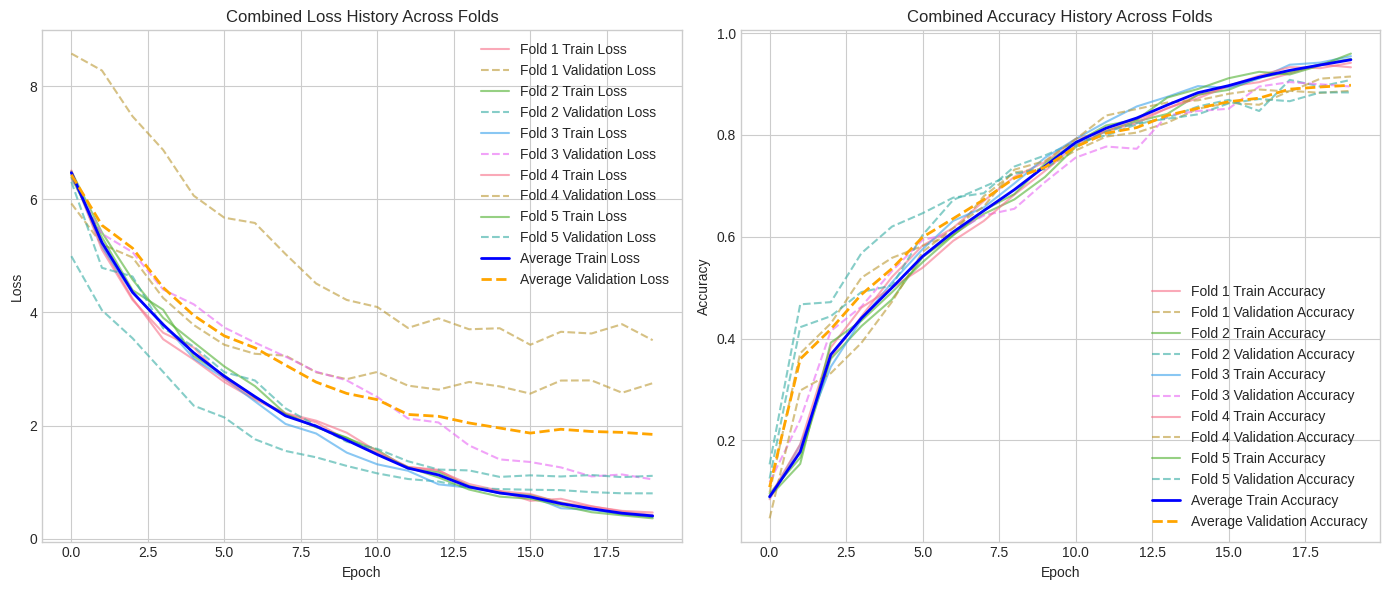

📊 Performing Calibration for Fold 1
📊 Performing Calibration for Fold 2
📊 Performing Calibration for Fold 3
📊 Performing Calibration for Fold 4
📊 Performing Calibration for Fold 5


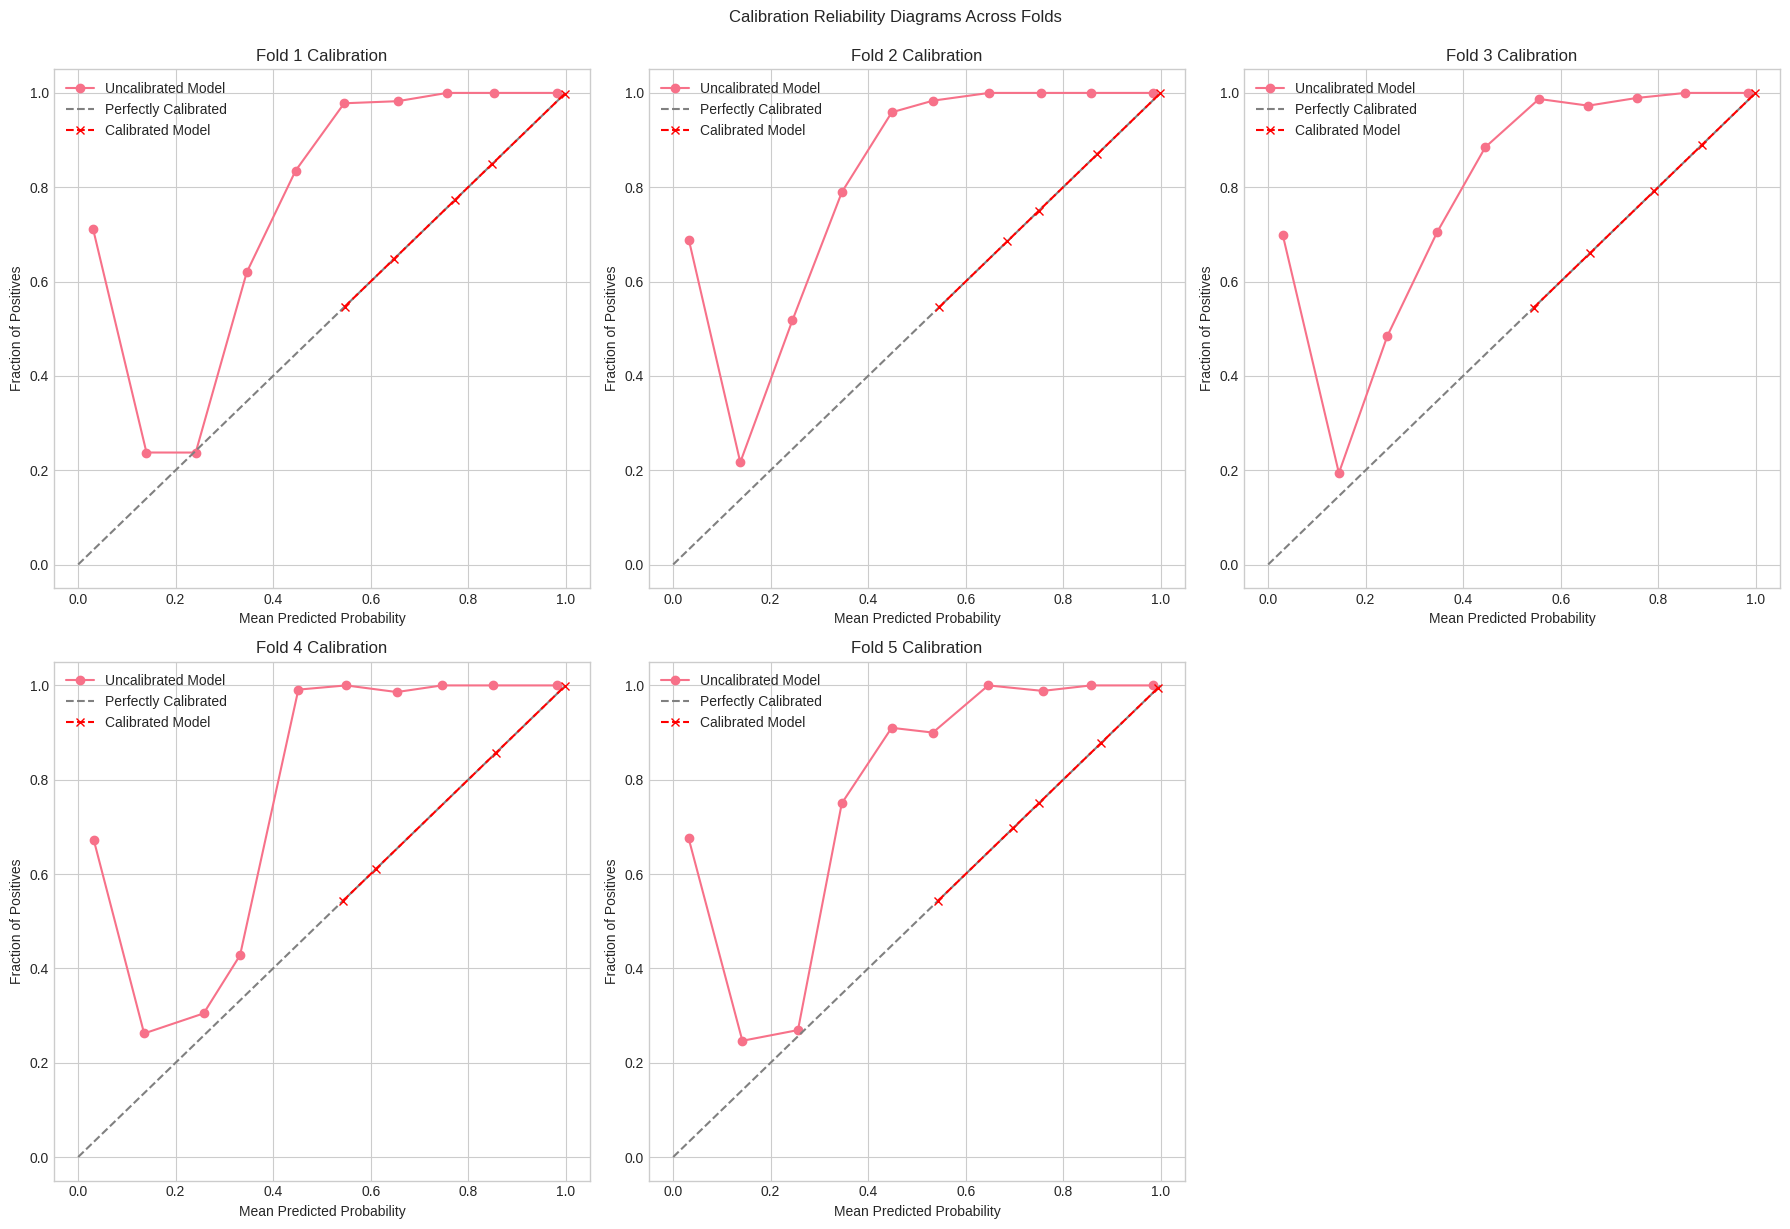

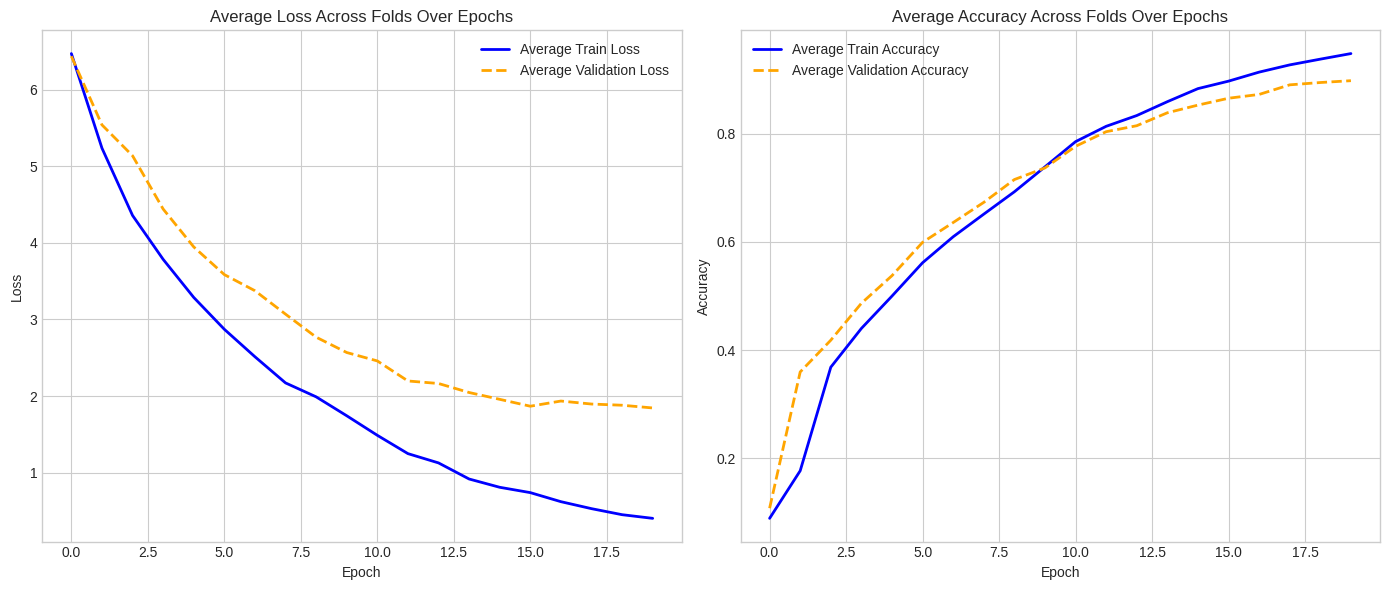

In [ ]:
    # Your existing training code
    config, dataset, best_model = main_training()

In [ ]:
import random
# print(dataset.node_features)
# print(dataset.edge_index)
# print(dataset[2])
    # --- انتخاب تصادفی یک سکانس تست ---
idx = random.randint(0, len(dataset)-1)
seq, tactics = dataset[idx]
print("seq:", seq)
print("tactics:", tactics)
dataset = CyberAttackDataset(config.data_dir)

seq: tensor([372, 341, 342,  81,   3,  96, 201, 203])
tactics: tensor([1, 2, 2, 3, 3, 3, 3, 3])


In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.calibration import calibration_curve, IsotonicRegression
import json
import collections

def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True

# قبل از فراخوانی main_testing
set_seed(42)  #


# Assuming AdvancedConfig, CyberAttackDataset, AdvancedCyberAttackPredictor,
# MultiTaskLoss, AdvancedMetrics, plot_calibration_curve, TemporalFeatureExtractor
# are defined in other cells

# ==================== MAIN TESTING PIPELINE ====================
def main_testing(config, dataset, best_model, training_pipeline=None):
    """
    Main testing function to evaluate the best model.

    Args:
        config: Configuration object with testing parameters.
        dataset: Dataset object containing token mappings and graph data.
        best_model: The trained model to evaluate (can be model instance or state_dict).
        training_pipeline: The AdvancedTrainingPipeline instance with precomputed features (optional).

    Returns:
        metrics: Evaluation metrics for the testing phase.
        calibration_data: Data for calibration (predicted_prob, true_label, technique_id) tuples.
    """
    print("🚀 Starting Testing Phase")

    # Initialize data loader for the entire dataset
    test_loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=True)
    print(f"test_loader:{len(test_loader)}")
    # Check if best_model is a state_dict and load it into a new model instance if necessary
    if isinstance(best_model, collections.OrderedDict):
        print("Loading model from state dictionary...")
        model_instance = AdvancedCyberAttackPredictor(
            dataset.vocab_size,
            dataset.node_features.size(-1),
            config.gnn_hidden_dim,
            config
        )
        model_instance.load_state_dict(best_model)
        model_to_evaluate = model_instance
    else:
        model_to_evaluate = best_model # Assume it's already a model instance

    # Move model to device and set to evaluation mode
    model_to_evaluate.to(config.device)
    model_to_evaluate.eval()

    # Access precomputed temporal features from the training pipeline if provided
    if training_pipeline is not None and hasattr(training_pipeline, 'precomputed_temporal_features'):
        precomputed_temporal_features = training_pipeline.precomputed_temporal_features
    else:
        # If pipeline or precomputed features are not available, you might need to
        # recompute them here or handle this case appropriately.
        # For now, we'll raise an error or skip temporal features if not available.
        print("Warning: Precomputed temporal features not available. Temporal features will be all zeros.")
        # Create zero tensor for temporal features if not available - this might impact performance
        precomputed_temporal_features = [
            torch.zeros(config.max_seq_len, config.temporal_feat_dim) for _ in range(len(dataset))
        ]


    # Initialize lists for metric calculation and calibration data
    all_true_tech = []
    all_pred_tech = []
    all_true_tactics = []
    all_pred_tactics = []
    testing_calibration_data = [] # Data for calibration on the test set

    criterion = MultiTaskLoss(config)
    total_loss = 0

    with torch.no_grad():
        for batch_idx, (batch_sequences, batch_tactics) in enumerate(test_loader):
            # Move data to device
            batch_sequences_device = batch_sequences.to(config.device)
            batch_tactics_device = batch_tactics.to(config.device)

            # Get precomputed temporal features for this batch
            # This assumes the dataset indices in the loader correspond to the precomputed list indices
            batch_indices = range(
                batch_idx * config.batch_size,
                min((batch_idx + 1) * config.batch_size, len(dataset)) # Ensure we don't go out of bounds
            )
            batch_temporal_features = torch.stack([
                precomputed_temporal_features[i] for i in batch_indices
            ]).to(config.device)


            # Forward pass
            outputs = model_to_evaluate(
                dataset.node_features.to(config.device),
                batch_sequences_device,
                dataset.edge_index.to(config.device),
                batch_temporal_features
            )

            # Calculate loss
            loss, _ = criterion(
                outputs,
                batch_sequences_device,
                batch_tactics_device
            )
            total_loss += loss.item()

            # Collect predictions and labels for metrics and calibration
            _, predicted_tech = torch.max(outputs['tech_logits'].data, 2)
            tech_probs = F.softmax(outputs['tech_logits'], dim=-1)

            # Move tensors to CPU for metric calculation
            predicted_tech_cpu = predicted_tech.cpu()
            sequences_cpu = batch_sequences.cpu()
            tactics_cpu = batch_tactics.cpu()
            tech_probs_cpu = tech_probs.cpu()

            # Create mask for non-padding elements
            non_pad_mask = sequences_cpu != config.pad_idx

            all_true_tech.extend(sequences_cpu[non_pad_mask].numpy())
            all_pred_tech.extend(predicted_tech_cpu[non_pad_mask].numpy())

            # Collect tactic predictions if available
            _, predicted_tactics = torch.max(outputs['tactic_logits'].data, 2)
            predicted_tactics_cpu = predicted_tactics.cpu()

            tactic_mask = tactics_cpu != -1
            all_true_tactics.extend(tactics_cpu[tactic_mask].numpy())
            all_pred_tactics.extend(predicted_tactics_cpu[tactic_mask].numpy())


            # Collect data for calibration (predicted probability of the true class)
            for i in range(sequences_cpu.size(0)):
                for j in range(sequences_cpu.size(1)):
                    if sequences_cpu[i, j] != config.pad_idx:
                        true_class = sequences_cpu[i, j].item()
                        predicted_prob = tech_probs_cpu[i, j, true_class].item()
                        testing_calibration_data.append((predicted_prob, 1, true_class)) # 1 for true class

                        # Also collect data for incorrect predictions (predicted probability of predicted class)
                        predicted_class = predicted_tech_cpu[i, j].item()
                        if predicted_class != true_class:
                            predicted_prob_incorrect = tech_probs_cpu[i, j, predicted_class].item()
                            testing_calibration_data.append((predicted_prob_incorrect, 0, predicted_class)) # 0 for incorrect class



    # Calculate overall average loss
    avg_loss = total_loss / len(test_loader)

    # Calculate overall metrics
    # Reuse the existing metrics calculation but also add confusion matrix and classification report
    metrics = {
        'loss': avg_loss,
        'technique_accuracy': accuracy_score(all_true_tech, all_pred_tech) if all_true_tech else 0,
        'technique_precision': precision_score(all_true_tech, all_pred_tech, average='weighted', zero_division=0) if all_true_tech else 0,
        'technique_recall': recall_score(all_true_tech, all_pred_tech, average='weighted', zero_division=0) if all_true_tech else 0,
        'technique_f1': f1_score(all_true_tech, all_pred_tech, average='weighted', zero_division=0) if all_true_tech else 0,
        'tactic_accuracy': accuracy_score(all_true_tactics, all_pred_tactics) if all_true_tactics else 0,
        'tactic_precision': precision_score(all_true_tactics, all_pred_tactics, average='weighted', zero_division=0) if all_true_tactics else 0,
        'tactic_recall': recall_score(all_true_tactics, all_pred_tactics, average='weighted', zero_division=0) if all_true_tactics else 0,
        'tactic_f1': f1_score(all_true_tactics, all_pred_tactics, average='weighted', zero_division=0) if all_true_tactics else 0,
        # Exact match calculation is more complex and might require sequence-level comparison
        # For now, we focus on per-technique/tactic metrics
        # 'exact_match': ...
    }

    print("✅ Testing Phase Completed")
    print("Testing Metrics:", metrics)

    # Add Confusion Matrix and Classification Report for Techniques
    if all_true_tech:
        print("\nTechnique Classification Report:")
        # Get unique labels for the classification report
        unique_tech_labels = sorted(list(set(all_true_tech) | set(all_pred_tech)))
        print(classification_report(all_true_tech, all_pred_tech, labels=unique_tech_labels, zero_division=0))

        print("\nTechnique Confusion Matrix:")
        cm_tech = confusion_matrix(all_true_tech, all_pred_tech, labels=unique_tech_labels)
        print(cm_tech)

    # Add Confusion Matrix and Classification Report for Tactics (if available)
    if all_true_tactics:
        print("\nTactic Classification Report:")
         # Get unique labels for the classification report
        unique_tactic_labels = sorted(list(set(all_true_tactics) | set(all_pred_tactics)))
        print(classification_report(all_true_tactics, all_pred_tactics, labels=unique_tactic_labels, zero_division=0))

        print("\nTactic Confusion Matrix:")
        cm_tactic = confusion_matrix(all_true_tactics, all_pred_tactics, labels=unique_tactic_labels)
        print(cm_tactic)


    # Plot calibration curve for the test set
    # We need to combine all calibration data from the test set
    if testing_calibration_data:
        predicted_probs = np.array([item[0] for item in testing_calibration_data])
        true_labels = np.array([item[1] for item in testing_calibration_data])

        plt.figure(figsize=(6, 6))
        # Plot uncalibrated reliability diagram for the test set
        plot_calibration_curve(
            true_labels,
            predicted_probs,
            title="Overall Test Set Calibration",
            label='Uncalibrated Model'
        )

        # Train and plot calibrated reliability diagram on the same subplot
        try:
             if len(np.unique(true_labels)) > 1 and len(predicted_probs) > 1:
                calibrator = IsotonicRegression(out_of_bounds="clip")
                calibrator.fit(predicted_probs, true_labels)
                calibrated_probs = calibrator.transform(predicted_probs)

                plot_calibration_curve(
                    true_labels,
                    calibrated_probs,
                    ax=plt.gca(), # Plot on the current axes
                    label='Calibrated Model',
                    n_bins=10 # Use default or specify n_bins
                )
                plt.legend() # Update legend


        except ValueError as e:
            print(f"Could not train calibrator for Test Set: {e}")
            print("Skipping calibrated reliability diagram for test set.")

        plt.tight_layout()
        plt.savefig(config.results_dir / 'overall_test_calibration_plot.png')
        plt.show()


    # Save test results
    # Include classification report and confusion matrix in saved results
    if all_true_tech:
        metrics['technique_classification_report'] = classification_report(all_true_tech, all_pred_tech, labels= unique_tech_labels, output_dict=True, zero_division= 0)
        metrics['technique_confusion_matrix'] = cm_tech.tolist() # Convert numpy array to list for JSON serialization

    if all_true_tactics:
         metrics['tactic_classification_report'] = classification_report(all_true_tactics, all_pred_tactics, labels=unique_tactic_labels, output_dict=True, zero_division=0)
         metrics['tactic_confusion_matrix'] = cm_tactic.tolist() # Convert numpy array to list

    with open(config.results_dir / 'testing_results.json', 'w') as f:
        json.dump(metrics, f, indent=2)


    return metrics, testing_calibration_data, all_true_tech, all_pred_tech

🚀 Starting Testing Phase
test_loader:6
Loading model from state dictionary...
✅ Testing Phase Completed
Testing Metrics: {'loss': 0.44415536522865295, 'technique_accuracy': 0.9754445385266723, 'technique_precision': 0.9619202182707687, 'technique_recall': 0.9754445385266723, 'technique_f1': 0.9668668447544774, 'tactic_accuracy': 0.9314140558848434, 'tactic_precision': 0.9367221719929912, 'tactic_recall': 0.9314140558848434, 'tactic_f1': 0.9295188927748614}

Technique Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        24
           2       1.00      1.00      1.00        11
           3       1.00      1.00      1.00        52
           4       1.00      1.00      1.00         4
           5       1.00      1.00      1.00         5
           6       0.67      1.00      0.80         4
           7       1.00      1.00      1.00         1
           8       1.00      1.00      1.00         1
          10      

<Figure size 600x600 with 0 Axes>

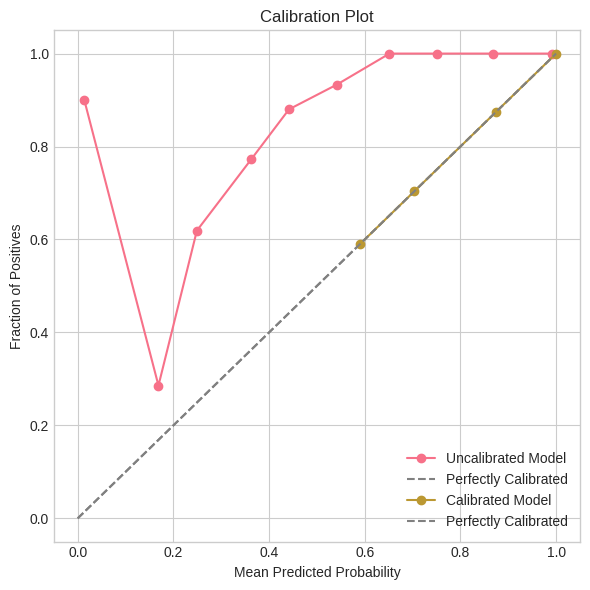

In [ ]:
metrics, testing_calibration_data, all_true_tech, all_pred_tech  = main_testing(config, dataset, best_model)

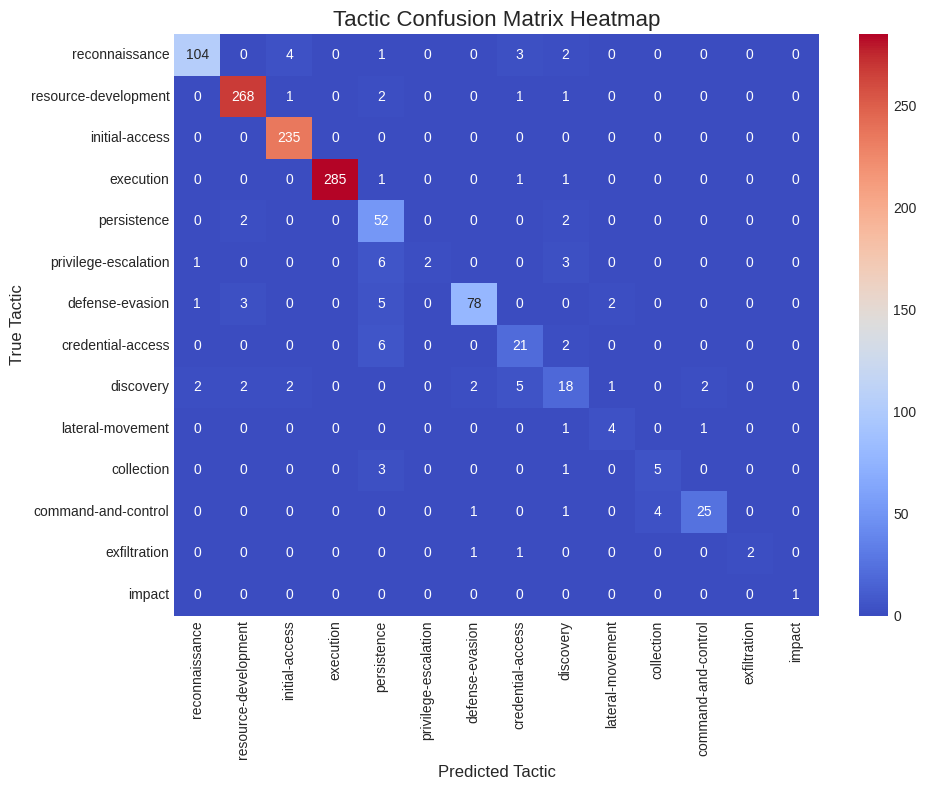

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Assuming 'metrics' dictionary is available from main_testing() execution
if 'tactic_confusion_matrix' in metrics and 'tactic_classification_report' in metrics:
    cm_tactic = np.array(metrics['tactic_confusion_matrix'])

    # Get the unique tactic labels from the classification report to ensure correct order
    # The keys of the classification report (excluding aggregates) are the labels
    tactic_report_data = metrics['tactic_classification_report']
    tactic_labels_in_report = [label for label in tactic_report_data.keys()
                               if label not in ['accuracy', 'macro avg', 'weighted avg']]
    # Sort them numerically if they are numbers, otherwise alphabetically
    try:
        tactic_labels_sorted = sorted(tactic_labels_in_report, key=int)
    except ValueError:
        tactic_labels_sorted = sorted(tactic_labels_in_report)


    # Convert numeric labels (indices) back to tactic names using the dataset or config
    # We need a mapping from the numeric index used in the confusion matrix to the tactic name
    # This mapping should come from where the tactic labels were created (likely config.tactic_order)
    # Let's assume the indices in the confusion matrix correspond to config.tactic_order
    # We need the config object or the dataset object that has the tactic_order
    # Assuming 'config' object is available from previous execution

    if 'config' in globals() and hasattr(config, 'tactic_order'):
        # Map the numeric indices back to tactic names
        # Ensure the size of cm_tactic matches the number of labels in config.tactic_order
        if cm_tactic.shape[0] == len(config.tactic_order):
             tactic_display_labels = config.tactic_order
        else:
             # Fallback or use the sorted labels from the report if sizes don't match perfectly
             tactic_display_labels = tactic_labels_sorted
             print(f"Warning: Confusion matrix size ({cm_tactic.shape[0]}) does not match config.tactic_order size ({len(config.tactic_order)}). Using report labels.")
    else:
        # If config or tactic_order is not available, just use the numeric labels as strings
        tactic_display_labels = [str(label) for label in tactic_labels_sorted]
        print("Warning: config object or tactic_order not available. Using numeric labels for heatmap.")


    # Plotting the heatmap
    plt.figure(figsize=(10, 8)) # Adjust size as needed
    sns.heatmap(cm_tactic, annot=True, fmt='d', cmap='coolwarm', cbar=True,
                xticklabels=tactic_display_labels,
                yticklabels=tactic_display_labels)

    plt.title('Tactic Confusion Matrix Heatmap', fontsize=16)
    plt.xlabel('Predicted Tactic', fontsize=12)
    plt.ylabel('True Tactic', fontsize=12)
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout() # Adjust layout
    plt.show()

else:
    print("Tactic Confusion Matrix data not found in the 'metrics' dictionary.")

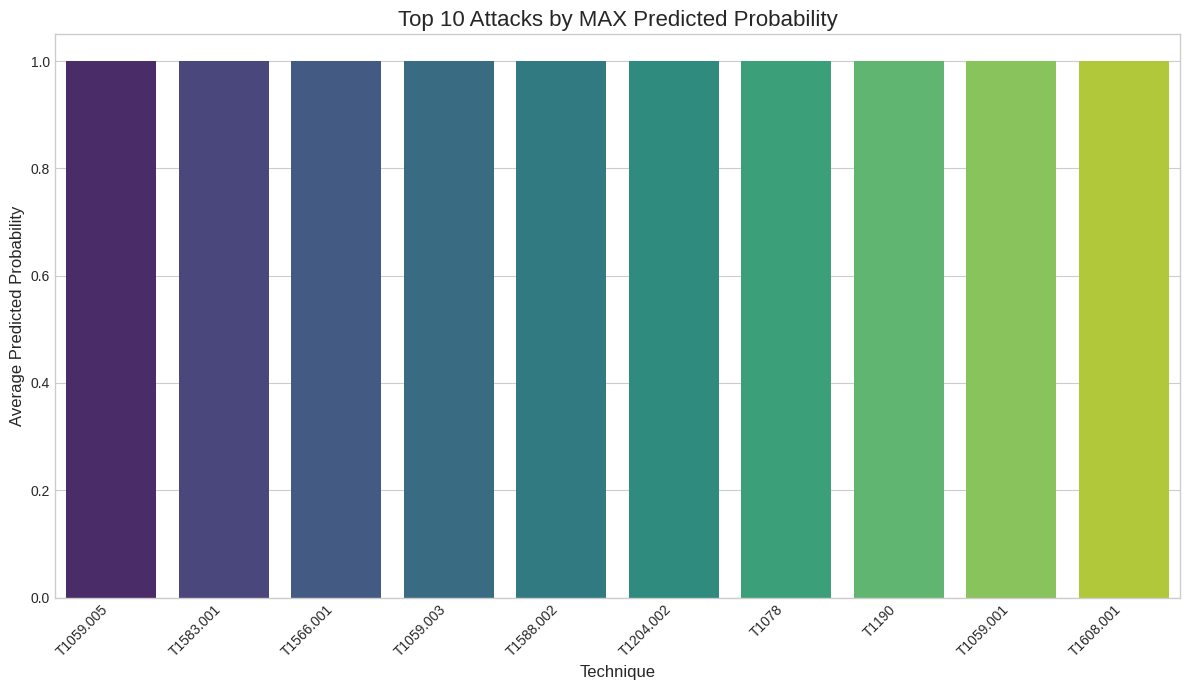

In [ ]:
#================== Top-N attacks + probable ==============

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# Assuming `metrics` and `testing_calibration_data` are available from the previous execution of main_testing()
# We need to extract the predicted probabilities and corresponding technique IDs from testing_calibration_data
# Note: testing_calibration_data contains (predicted_prob, true_label, technique_id) tuples
# We are interested in the predicted probability and the technique_id

# Extract predicted probabilities and technique IDs for all predictions
predicted_probs_all = np.array([item[0] for item in testing_calibration_data])
technique_ids_all = np.array([item[2] for item in testing_calibration_data])

# Get the technique names from the dataset's idx_to_token mapping
# Assuming 'dataset' object is available from previous execution
if 'dataset' in globals() and hasattr(dataset, 'idx2token'):
    idx_to_token_mapping = dataset.idx2token
else:
    idx_to_token_mapping = {i: str(i) for i in np.unique(technique_ids_all)}
    print("Warning: dataset object not available. Using numeric IDs as labels for the bar chart.")

# Create a DataFrame to easily group and aggregate
prediction_df = pd.DataFrame({
    'technique_id': technique_ids_all,
    'predicted_prob': predicted_probs_all
})

# Calculate the average predicted probability for each technique
average_probs = prediction_df.groupby('technique_id')['predicted_prob'].max().reset_index()

# Add technique names
average_probs['technique_name'] = average_probs['technique_id'].map(idx_to_token_mapping)

# Sort by average probability in descending order
average_probs = average_probs.sort_values(by='predicted_prob', ascending=False)

# Select the top N attacks
N = 10 # You can adjust N as needed
top_n_attacks = average_probs.head(N)

# Plotting the bar chart
plt.figure(figsize=(12, 7))
sns.barplot(x='technique_name', y='predicted_prob', data=top_n_attacks, palette='viridis')

plt.title(f'Top {N} Attacks by MAX Predicted Probability', fontsize=16)
plt.xlabel('Technique', fontsize=12)
plt.ylabel('Average Predicted Probability', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

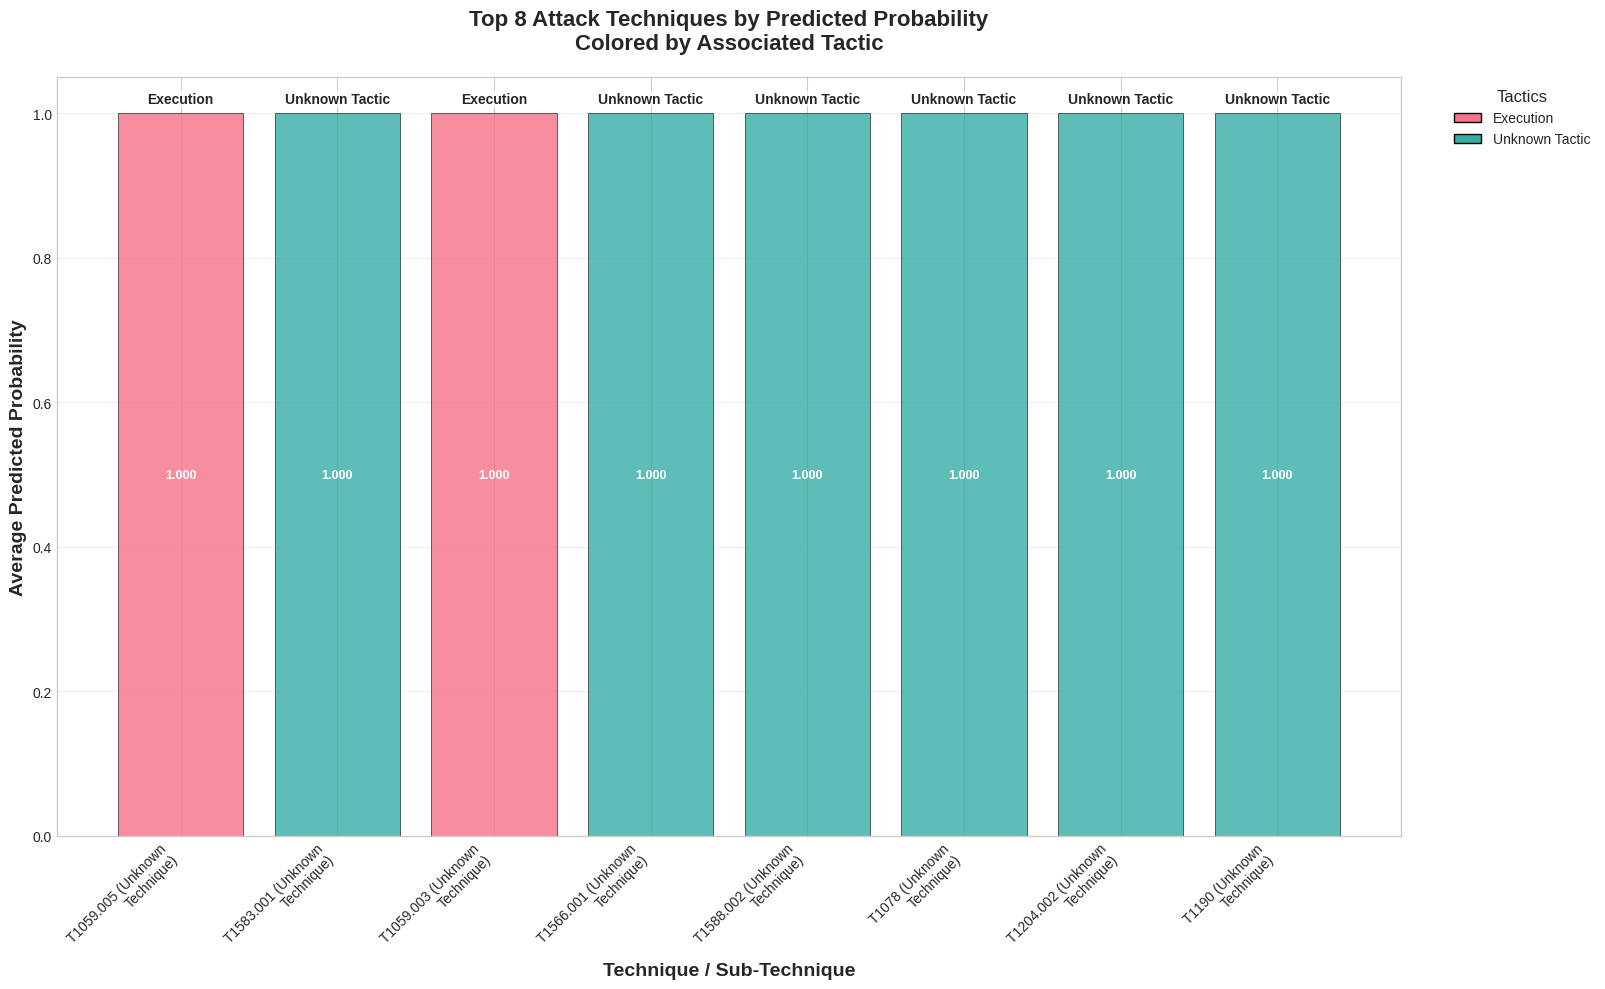

📊 Summary Statistics for Top Attacks:
Technique         Tactic  Avg Probability  Rank
T1059.005      Execution         0.999838     1
T1583.001 Unknown Tactic         0.999801     2
T1059.003      Execution         0.999799     3
T1566.001 Unknown Tactic         0.999785     4
T1588.002 Unknown Tactic         0.999761     5
    T1078 Unknown Tactic         0.999712     6
T1204.002 Unknown Tactic         0.999700     7
    T1190 Unknown Tactic         0.999675     8


In [ ]:
# ================== Enhanced Top-N Attacks Visualization ==============
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.patches import Patch
import textwrap

def plot_enhanced_top_n_attacks(config, testing_calibration_data, dataset, n_attacks=10):
    """
    ایجاد نمودار حرفه‌ای برای نمایش برترین حملات پیش‌بینی شده

    Args:
        config: شیء پیکربندی
        testing_calibration_data: داده‌های کالیبراسیون از main_testing
        dataset: dataset object
        n_attacks: تعداد حملات برتر برای نمایش
    """

    # استخراج داده‌های پیش‌بینی
    predicted_probs_all = np.array([item[0] for item in testing_calibration_data])
    technique_ids_all = np.array([item[2] for item in testing_calibration_data])

    # ایجاد DataFrame برای آنالیز
    prediction_df = pd.DataFrame({
        'technique_id': technique_ids_all,
        'predicted_prob': predicted_probs_all
    })

    # محاسبه میانگین احتمالات برای هر تکنیک
    average_probs = prediction_df.groupby('technique_id')['predicted_prob'].mean().reset_index()

    # افزودن نام تکنیک‌ها
    average_probs['technique_name'] = average_probs['technique_id'].map(dataset.idx2token)

    # مرتب‌سازی بر اساس احتمال
    average_probs = average_probs.sort_values(by='predicted_prob', ascending=False)

    # انتخاب N حمله برتر
    top_n_attacks = average_probs.head(n_attacks).copy()

    # افزودن نام تاکتیک‌های مرتبط
    top_n_attacks['tactic_name'] = top_n_attacks['technique_id'].apply(
        lambda x: get_tactic_for_technique(config, x)
    )

    # ایجاد نام نمایشی برای تکنیک‌ها (شامل نام توصیفی)
    top_n_attacks['display_name'] = top_n_attacks.apply(
        lambda row: f"{row['technique_name']}\n({get_technique_description(row['technique_name'])})",
        axis=1
    )

    # ایجاد رنگ‌بندی بر اساس تاکتیک‌ها
    unique_tactics = top_n_attacks['tactic_name'].unique()
    color_palette = sns.color_palette("husl", len(unique_tactics))
    tactic_colors = {tactic: color_palette[i] for i, tactic in enumerate(unique_tactics)}
    top_n_attacks['color'] = top_n_attacks['tactic_name'].map(tactic_colors)

    # ایجاد نمودار
    plt.figure(figsize=(16, 10))
    ax = plt.subplot(111)

    # رسم نمودار میله‌ای
    bars = ax.bar(range(len(top_n_attacks)),
                 top_n_attacks['predicted_prob'],
                 color=top_n_attacks['color'],
                 alpha=0.8,
                 edgecolor='black',
                 linewidth=0.5)

    # افزودن نام تاکتیک در بالای هر میله
    for i, (bar, tactic) in enumerate(zip(bars, top_n_attacks['tactic_name'])):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
               tactic, ha='center', va='bottom',
               fontsize=10, fontweight='bold',
               bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

    # تنظیمات محورها
    ax.set_xlabel('Technique / Sub-Technique', fontsize=14, fontweight='bold')
    ax.set_ylabel('Average Predicted Probability', fontsize=14, fontweight='bold')
    ax.set_title(f'Top {n_attacks} Attack Techniques by Predicted Probability\nColored by Associated Tactic',
                fontsize=16, fontweight='bold', pad=20)

    # تنظیم محور X
    ax.set_xticks(range(len(top_n_attacks)))
    wrapped_labels = [textwrap.fill(label, 20) for label in top_n_attacks['display_name']]
    ax.set_xticklabels(wrapped_labels, fontsize=10, rotation=45, ha='right')

    # افزودن شبکه‌بندی
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_axisbelow(True)

    # ایجاد legend برای تاکتیک‌ها
    legend_elements = [Patch(facecolor=tactic_colors[tactic],
                            label=tactic,
                            edgecolor='black') for tactic in unique_tactics]
    ax.legend(handles=legend_elements,
             title='Tactics',
             title_fontsize=12,
             fontsize=10,
             loc='upper right',
             bbox_to_anchor=(1.15, 1))

    # افزودن مقادیر عددی روی میله‌ها
    for i, bar in enumerate(bars):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height/2,
               f'{height:.3f}', ha='center', va='center',
               fontsize=9, fontweight='bold', color='white')

    # تنظیم layout
    plt.tight_layout()

    # ذخیره نمودار
    output_path = config.results_dir / f'top_{n_attacks}_attacks_analysis.png'
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()

    # ایجاد جدول خلاصه آمار
    summary_table = top_n_attacks[['technique_name', 'tactic_name', 'predicted_prob']].copy()
    summary_table.columns = ['Technique', 'Tactic', 'Avg Probability']
    summary_table['Rank'] = range(1, len(summary_table) + 1)

    print("📊 Summary Statistics for Top Attacks:")
    print(summary_table.to_string(index=False))

    return output_path, summary_table

# توابع کمکی
def get_tactic_for_technique(config, technique_id):
    """
    یافتن تاکتیک مرتبط با یک تکنیک
    """
    technique_name = dataset.idx2token.get(technique_id, f"T{technique_id}")

    # این بخش بستگی به ساختار داده‌های شما دارد
    # اگر mapping مستقیم وجود دارد از آن استفاده کنید
    if hasattr(config, 'technique_to_tactic'):
        return config.technique_to_tactic.get(technique_name, "Unknown Tactic")

    # یا از طریق dataset mapping انجام دهید
    elif hasattr(dataset, 'technique_tactic_mapping'):
        return dataset.technique_tactic_mapping.get(technique_name, "Unknown Tactic")

    # یا از یک منبع خارجی استفاده کنید
    else:
        # در اینجا می‌توانید یک mapping ثابت تعریف کنید
        tactic_mapping = {
            'T1059': 'Execution',
            'T1059.001': 'Execution',
            'T1071': 'Command and Control',
            # ... mappingهای دیگر
        }
        base_tech = technique_name.split('.')[0]  # برای ساب-تکنیک‌ها
        return tactic_mapping.get(base_tech, "Unknown Tactic")

def get_technique_description(technique_code):
    """
    دریافت نام توصیفی تکنیک بر اساس کد آن
    """
    # این mapping باید از منبعی مانند MITRE ATT&CK پر شود
    technique_descriptions = {
        'T1059': 'Command and Scripting Interpreter',
        'T1059.001': 'PowerShell',
        'T1071': 'Application Layer Protocol',
        # ... descriptions دیگر
    }
    return technique_descriptions.get(technique_code, "Unknown Technique")

# نحوه استفاده از تابع
output_path, summary = plot_enhanced_top_n_attacks(config, testing_calibration_data, dataset, n_attacks=8)

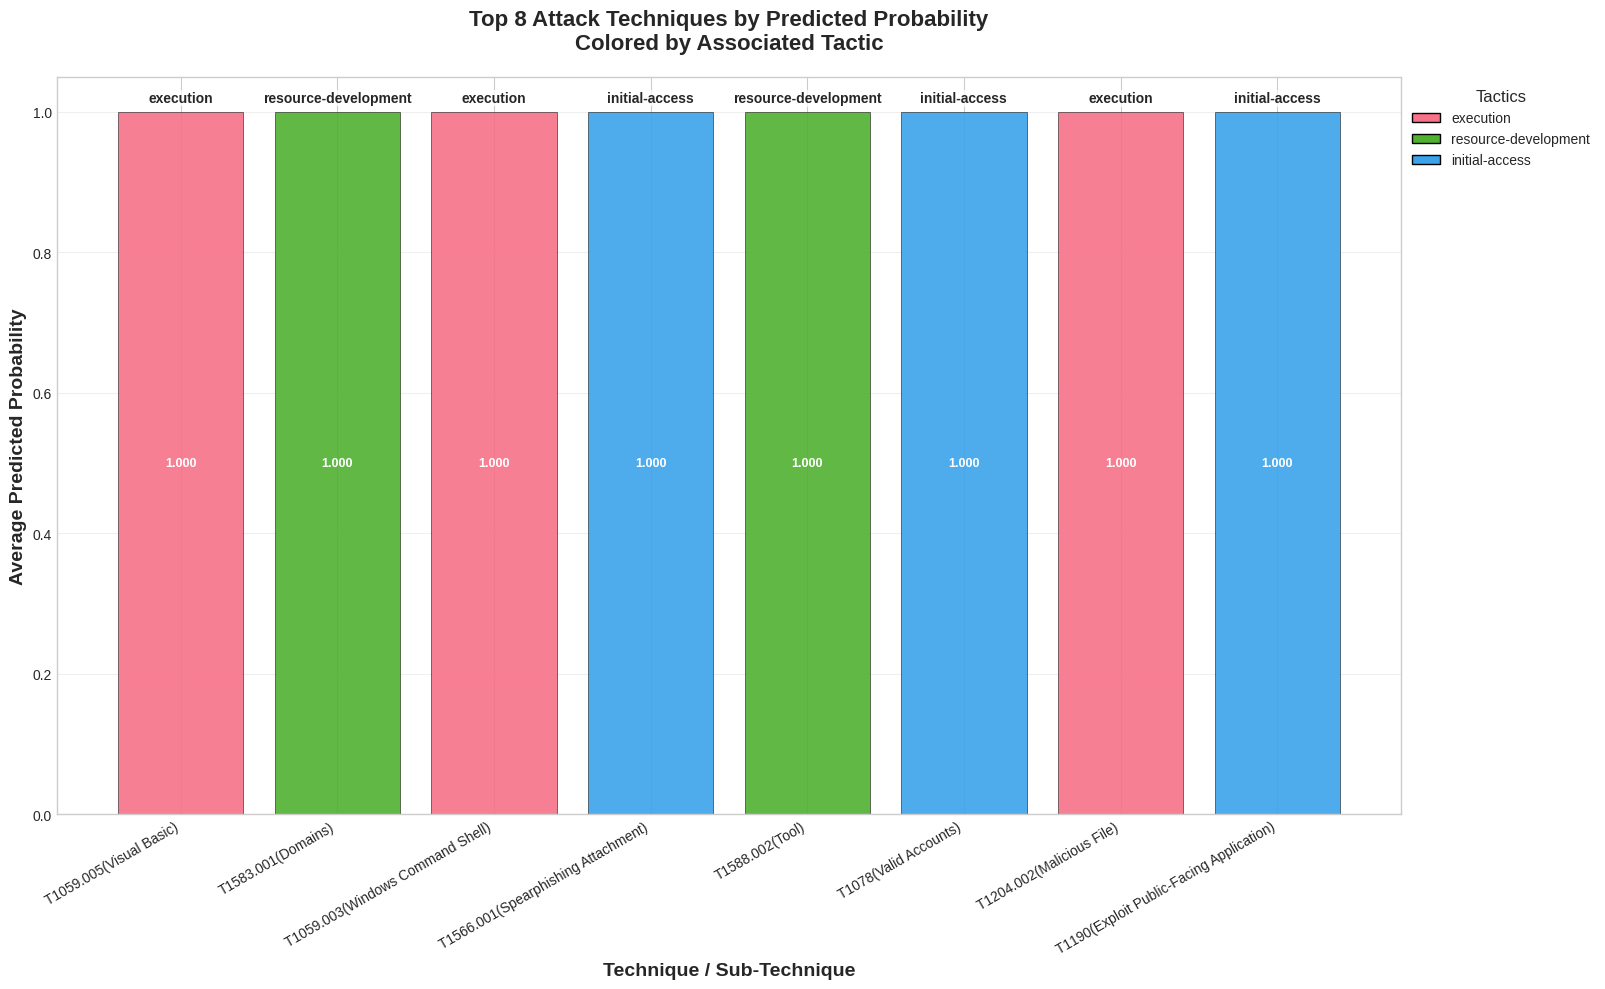

📊 Summary Statistics for Top Attacks:
Technique                    Technique Name               Tactic  Avg Probability  Rank
T1059.005                      Visual Basic            execution         0.999838     1
T1583.001                           Domains resource-development         0.999801     2
T1059.003             Windows Command Shell            execution         0.999799     3
T1566.001          Spearphishing Attachment       initial-access         0.999785     4
T1588.002                              Tool resource-development         0.999761     5
    T1078                    Valid Accounts       initial-access         0.999712     6
T1204.002                    Malicious File            execution         0.999700     7
    T1190 Exploit Public-Facing Application       initial-access         0.999675     8


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import textwrap
import json
from pathlib import Path
from typing import Tuple, Optional, Any

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import textwrap
import json
from pathlib import Path
from typing import Tuple, Optional, Any

def _load_json_values(path):
    p = Path(path)
    if not p.exists():
        return []
    with open(p, "r", encoding="utf-8") as f:
        data = json.load(f)
    # normalize: if dict -> return list of values, if list -> return as-is
    if isinstance(data, dict):
        try:
            return list(data.values())
        except Exception:
            return []
    elif isinstance(data, list):
        return data
    else:
        return []

def _safe_get_pred_and_tid(item):
    """پذیرش چند فرمت مختلف برای testing_calibration_data"""
    if isinstance(item, (list, tuple)):
        pred = item[0] if len(item) > 0 else None
        tid = None
        # common places for technique id: index 2 or last element if string-like
        if len(item) > 2:
            tid = item[2]
        elif len(item) > 0 and isinstance(item[-1], (str, int)):
            tid = item[-1]
        return pred, tid
    if isinstance(item, dict):
        pred = item.get("predicted_prob") or item.get("pred") or item.get("prob") or item.get("score")
        tid = item.get("technique_id") or item.get("tech") or item.get("tid") or item.get("technique")
        return pred, tid
    return None, None

def plot_enhanced_top_n_attacks(config: Any,
                                testing_calibration_data: list,
                                dataset: Optional[Any] = None,
                                n_attacks: int = 10,
                                mapping_folder: str = "/content/data") -> Tuple[Path, pd.DataFrame]:
    """
    نسخهٔ نهایی که display label را به شکل T1059.001(PowerShell) می‌سازد
    و از tactic_technique_details.json / idx2token.json استفاده می‌کند.
    """

    # --- بارگذاری mappingها ---
    mapping_folder = Path(mapping_folder)
    tactic_detail_path = mapping_folder / "tactic_technique_details.json"
    idx2token_path = mapping_folder / "idx2token.json"

    tactic_details = _load_json_values(tactic_detail_path)
    technique_to_tactic = {}
    technique_to_name = {}
    technique_to_desc = {}

    for item in tactic_details:
        # handle different key namings
        tid = item.get("technique_id") or item.get("technique") or item.get("technique_id")
        if not tid:
            continue
        tid_s = str(tid).upper()
        technique_to_tactic[tid_s] = item.get("tactic", "unknown")
        # some files may store technique_name as 'technique_name' or 'technique_name'
        technique_to_name[tid_s] = item.get("technique_name") or item.get("technique_name") or item.get("technique_name", tid_s)
        technique_to_desc[tid_s] = item.get("description", "") or item.get("desc", "")

    # بارگذاری idx2token (fallback)
    idx2token = {}
    if dataset is not None and hasattr(dataset, "idx2token") and isinstance(dataset.idx2token, dict):
        idx2token = {str(k): v for k, v in dataset.idx2token.items()}
    else:
        try:
            with open(idx2token_path, "r", encoding="utf-8") as f:
                raw = json.load(f)
            if isinstance(raw, dict):
                # keys may be numeric or string
                idx2token = {str(k): v for k, v in raw.items()}
            else:
                idx2token = {}
        except Exception:
            idx2token = {}

    def resolve_tid(tid):
        """Resolve technique id: if numeric index -> use idx2token, else pass through and uppercase TIDs"""
        if tid is None:
            return None
        try:
            if isinstance(tid, (int, np.integer)):
                s = str(int(tid))
                if s in idx2token:
                    return idx2token[s]
                return s
            if isinstance(tid, str):
                # numeric string?
                if tid.isdigit() and tid in idx2token:
                    return idx2token[tid]
                return tid.upper()
        except Exception:
            return str(tid)
        return str(tid)

    # استخراج پیش‌بینی‌ها و تکنیک‌ها
    preds = []
    tids = []
    for itm in testing_calibration_data:
        pred, tid = _safe_get_pred_and_tid(itm)
        preds.append(pred)
        tids.append(tid)

    preds = np.array(preds, dtype=float)
    resolved_tids = [resolve_tid(t) for t in tids]

    mask_valid = [ (p is not None and (t is not None and str(t) != "nan")) for p,t in zip(preds, resolved_tids) ]
    if not any(mask_valid):
        raise ValueError("هیچ تکنیکی از testing_calibration_data قابل‌شناسایی نبود. ساختار داده را بررسی کنید.")

    preds = preds[mask_valid]
    resolved_tids = [str(t) for t, ok in zip(resolved_tids, mask_valid) if ok]

    prediction_df = pd.DataFrame({
        "technique_id": resolved_tids,
        "predicted_prob": preds
    })

    # میانگین احتمالات
    average_probs = prediction_df.groupby("technique_id", as_index=False)["predicted_prob"].mean()

    # helperها برای name/tactic/desc
    def get_name_for_tid(tid):
        tid_u = str(tid).upper()
        if tid_u in technique_to_name and technique_to_name[tid_u]:
            return technique_to_name[tid_u]
        # try without uppercase
        if tid in technique_to_name and technique_to_name[tid]:
            return technique_to_name[tid]
        return tid_u

    def get_tactic_for_tid(tid):
        tid_u = str(tid).upper()
        return technique_to_tactic.get(tid_u, "unknown")

    def get_desc_for_tid(tid):
        tid_u = str(tid).upper()
        return technique_to_desc.get(tid_u, "")

    average_probs["technique_name"] = average_probs["technique_id"].apply(get_name_for_tid)
    average_probs["tactic_name"] = average_probs["technique_id"].apply(get_tactic_for_tid)
    average_probs["description"] = average_probs["technique_id"].apply(get_desc_for_tid)

    # ---------- ساخت label به صورت T1059.001(PowerShell) ----------
    def build_display_label(tid, name, desc=None, max_chars=60):
        if tid is None:
            return "Unknown"
        tid_str = str(tid).upper()
        short_name = name.strip() if isinstance(name, str) and name else ""
        if short_name:
            label = f"{tid_str}({short_name})"
        else:
            label = tid_str
        # کوتاه سازی هوشمند در صورت خیلی طولانی بودن
        if len(label) > max_chars:
            if "(" in label and ")" in label:
                tid_part = tid_str
                inside = short_name
                allowed = max(10, max_chars - len(tid_part) - 5)
                inside_short = (inside[:allowed] + "...") if len(inside) > allowed else inside
                label = f"{tid_part}({inside_short})"
            else:
                label = label[:max_chars-3] + "..."
        return label

    average_probs = average_probs.sort_values(by="predicted_prob", ascending=False).reset_index(drop=True)
    top_n_attacks = average_probs.head(n_attacks).copy()

    top_n_attacks["display_name"] = top_n_attacks.apply(
        lambda r: build_display_label(r["technique_id"], r["technique_name"], r.get("description", "")),
        axis=1
    )

    # رنگ بندی بر اساس تاکتیک
    unique_tactics = list(top_n_attacks["tactic_name"].unique())
    if len(unique_tactics) == 0:
        unique_tactics = ["unknown"]
    color_palette = sns.color_palette("husl", len(unique_tactics))
    tactic_colors = {t: color_palette[i] for i, t in enumerate(unique_tactics)}
    top_n_attacks["color"] = top_n_attacks["tactic_name"].map(tactic_colors)

    # رسم نمودار
    results_dir = Path(getattr(config, "results_dir", "./results"))
    results_dir.mkdir(parents=True, exist_ok=True)
    output_path = results_dir / f"top_{n_attacks}_attacks_analysis.png"

    plt.figure(figsize=(16, 10))
    ax = plt.subplot(111)

    bars = ax.bar(range(len(top_n_attacks)),
                  top_n_attacks["predicted_prob"],
                  color=list(top_n_attacks["color"]),
                  alpha=0.9,
                  edgecolor="black",
                  linewidth=0.4)

    # نام تاکتیک بالای میله ها
    for i, (bar, tactic) in enumerate(zip(bars, top_n_attacks["tactic_name"])):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                tactic, ha="center", va="bottom",
                fontsize=10, fontweight="bold",
                bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1))

    ax.set_xlabel("Technique / Sub-Technique", fontsize=14, fontweight="bold")
    ax.set_ylabel("Average Predicted Probability", fontsize=14, fontweight="bold")
    ax.set_title(f"Top {n_attacks} Attack Techniques by Predicted Probability\nColored by Associated Tactic",
                 fontsize=16, fontweight="bold", pad=20)

    ax.set_xticks(range(len(top_n_attacks)))
    ax.set_xticklabels(list(top_n_attacks["display_name"]), fontsize=10, rotation=30, ha="right")

    ax.grid(True, alpha=0.3, axis="y")
    ax.set_axisbelow(True)

    legend_elements = [Patch(facecolor=tactic_colors[t], label=t, edgecolor="black") for t in unique_tactics]
    ax.legend(handles=legend_elements,
              title="Tactics",
              title_fontsize=12,
              fontsize=10,
              loc="upper right",
              bbox_to_anchor=(1.15, 1))

    # مقادیر عددی روی میله‌ها
    for i, bar in enumerate(bars):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height/2,
                f"{height:.3f}", ha="center", va="center",
                fontsize=9, fontweight="bold", color="white")

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    # جدول خلاصه
    summary_table = top_n_attacks[["technique_id", "technique_name", "tactic_name", "predicted_prob"]].copy()
    summary_table.columns = ["Technique", "Technique Name", "Tactic", "Avg Probability"]
    summary_table["Rank"] = range(1, len(summary_table) + 1)
    summary_table = summary_table.sort_values("Rank").reset_index(drop=True)

    print("📊 Summary Statistics for Top Attacks:")
    print(summary_table.to_string(index=False))

    return output_path, summary_table

output_path, summary = plot_enhanced_top_n_attacks(config, testing_calibration_data, dataset=dataset, n_attacks=8)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score

def plot_sequence_predictions(dataset, all_true_tech, all_pred_tech, config, num_sequences=1):
    """
    Plot true vs predicted sequences for a few examples.

    Args:
        dataset: Dataset object containing token mappings
        all_true_tech: List of true technique indices
        all_pred_tech: List of predicted technique indices
        config: Configuration object
        num_sequences: Number of sequences to plot
    """
    # Convert flat lists back to sequences
    true_sequences = []
    pred_sequences = []

    # We need to reconstruct sequences from the flat lists
    # This assumes the test data was processed in order
    # and we know the original sequence lengths
    # For simplicity, we'll just take the first few sequences
    # and assume they have the same length as in the dataset

    # Get the first few sequences from the dataset
    for i in range(min(num_sequences, len(dataset))):
        true_seq, _ = dataset[i]
        # Remove padding
        true_seq = true_seq[true_seq != config.pad_idx].tolist()
        true_sequences.append(true_seq)

        # Get the corresponding predictions
        start_idx = i * len(true_seq)
        end_idx = start_idx + len(true_seq)
        pred_seq = all_pred_tech[start_idx:end_idx]
        pred_sequences.append(pred_seq)

    # Plot the sequences
    fig, axes = plt.subplots(num_sequences, 1, figsize=(12, 3*num_sequences))
    if num_sequences == 1:
        axes = [axes]

    for i, (true_seq, pred_seq) in enumerate(zip(true_sequences, pred_sequences)):
        min_len = min(len(true_seq), len(pred_seq))
        true_seq = true_seq[:min_len]
        pred_seq = pred_seq[:min_len]

        # Convert indices to technique names
        true_tech_names = [dataset.idx2token.get(idx, 'UNK') for idx in true_seq]
        pred_tech_names = [dataset.idx2token.get(idx, 'UNK') for idx in pred_seq]

        # Create x-axis labels with technique names
        x_labels = [f"{true_tech_names[j]}\n({pred_tech_names[j]})" for j in range(min_len)]

        axes[i].plot(range(min_len), true_seq, 'o-', label='True')
        axes[i].plot(range(min_len), pred_seq, 's-', label='Predicted')
        axes[i].set_title(f'Sequence {i+1} - True vs Predicted')
        axes[i].set_xlabel('Step (True Technique\nPredicted Technique)')
        axes[i].set_ylabel('Technique Index')
        axes[i].set_xticks(range(min_len))
        axes[i].set_xticklabels(x_labels, rotation=45, ha='right')
        axes[i].legend()
        axes[i].grid(True)

    plt.tight_layout()
    plt.savefig(config.results_dir / 'sequence_predictions_plot.png')
    plt.show()

def plot_prediction_accuracy(all_true_tech, all_pred_tech, config):
    """
    Plot prediction accuracy at each step across all sequences.

    Args:
        all_true_tech: List of true technique indices
        all_pred_tech: List of predicted technique indices
        config: Configuration object
    """
    # For this visualization, we need to know the length of each sequence
    # Since we don't have that information, we'll calculate accuracy
    # at each position assuming all sequences have the same length
    # or we'll use the maximum length found

    # Find the maximum sequence length
    max_len = max(len(seq) for seq in dataset.sequences) if hasattr(dataset, 'sequences') else config.max_seq_len

    # Calculate accuracy at each step
    step_accuracies = []

    for step in range(max_len):
        step_true = []
        step_pred = []

        # We need to reconstruct the step for each sequence
        # This is a simplified approach
        for i in range(len(all_true_tech)):
            # This assumes the data is ordered by sequence and step
            # which may not be accurate
            if i % max_len == step and i < len(all_pred_tech):
                step_true.append(all_true_tech[i])
                step_pred.append(all_pred_tech[i])

        if step_true and step_pred:
            accuracy = accuracy_score(step_true, step_pred)
            step_accuracies.append(accuracy)
        else:
            step_accuracies.append(0)

    plt.figure(figsize=(10, 5))
    plt.plot(range(len(step_accuracies)), step_accuracies, 'o-')
    plt.title('Prediction Accuracy at Each Step')
    plt.xlabel('Step')
    plt.ylabel('Accuracy')
    plt.grid(True)
    plt.savefig(config.results_dir / 'prediction_accuracy_plot.png')
    plt.show()

    return step_accuracies

def plot_probability_distribution(testing_calibration_data, config):
    """
    Plot probability distribution of predictions.

    Args:
        testing_calibration_data: List of (predicted_prob, true_label, technique_id) tuples
        config: Configuration object
    """
    # Extract probabilities
    probs = [item[0] for item in testing_calibration_data]

    plt.figure(figsize=(10, 5))
    plt.hist(probs, bins=20, alpha=0.7, edgecolor='black')
    plt.title('Probability Distribution of Predictions')
    plt.xlabel('Predicted Probability')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.savefig(config.results_dir / 'probability_distribution_plot.png')
    plt.show()

    # Also plot calibration curve
    true_labels = [item[1] for item in testing_calibration_data]

    plt.figure(figsize=(6, 6))
    plot_calibration_curve(
        true_labels,
        probs,
        title="Test Set Calibration Curve",
        label='Model Predictions'
    )
    plt.savefig(config.results_dir / 'calibration_curve_plot.png')
    plt.show()

def plot_technique_confidence(predictions, dataset, config):
    """
    Plot confidence levels for each predicted technique.

    Args:
        predictions: Output from Attack_sequence_prediction
        dataset: Dataset object
        config: Configuration object
    """
    techniques = predictions['technique_names']
    probs = predictions['probabilities']

    plt.figure(figsize=(12, 6))
    plt.bar(range(len(techniques)), probs, color='skyblue', alpha=0.7)
    plt.xlabel('Prediction Step')
    plt.ylabel('Confidence')
    plt.title('Prediction Confidence for Each Technique')
    plt.xticks(range(len(techniques)), techniques, rotation=45, ha='right')
    plt.grid(True, axis='y')
    plt.tight_layout()
    plt.savefig(config.results_dir / 'technique_confidence_plot.png')
    plt.show()



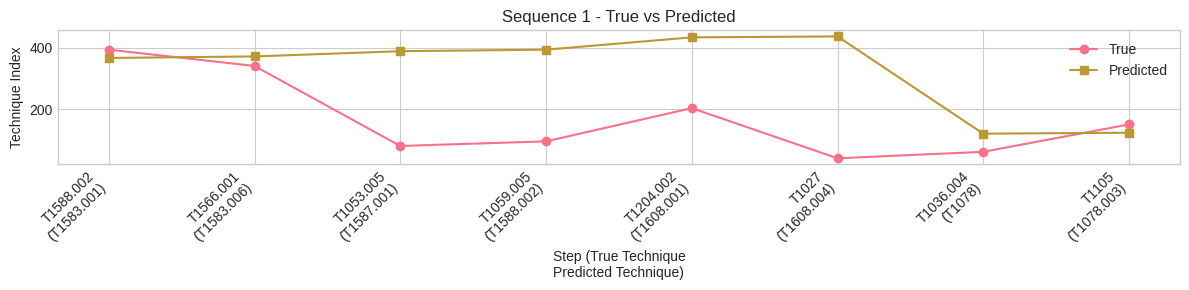

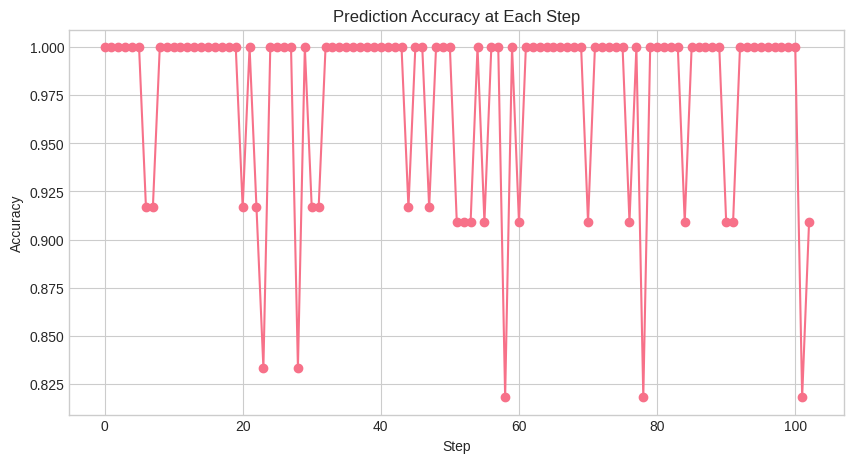

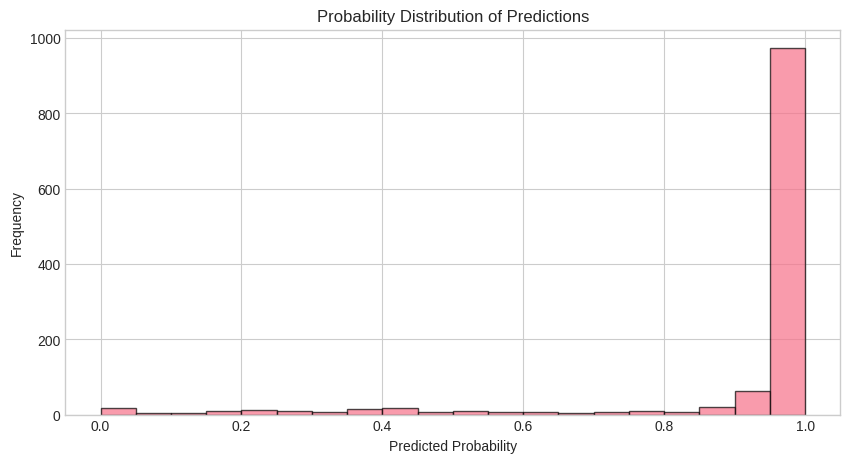

<Figure size 600x600 with 0 Axes>

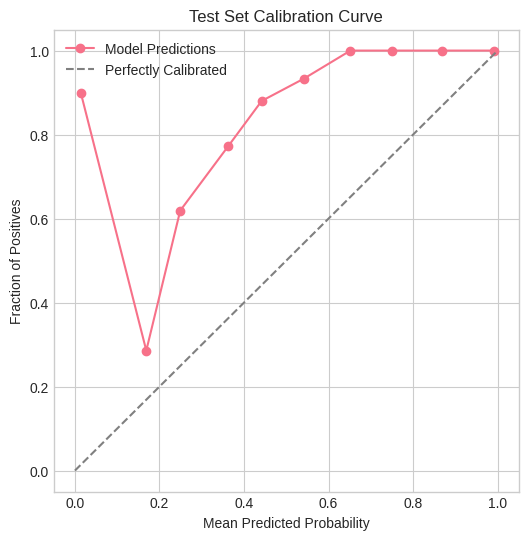

In [ ]:
plot_sequence_predictions(dataset, all_true_tech, all_pred_tech, config)
plot_prediction_accuracy(all_true_tech, all_pred_tech, config)
plot_probability_distribution(testing_calibration_data, config)